

**Klas:** Den Haag 2A
**Teamnaam:** 'Roemer Breedveld'
**Groep:** 5


| Teamlid | Kaggle-gebruikersnaam |
|---------|-----------------------|
| *Lars* | *larsolssonn* |
| *Sven* | *svenkr6* |
| *Roemer* | *roemerbreedveld* |

# Machine learning stroke prediction


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, RandomizedSearchCV, GridSearchCV, TunedThresholdClassifierCV
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from scipy.stats import randint, uniform, loguniform
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, precision_recall_curve
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import cross_val_score
from sklearn.metrics import f1_score
from sklearn.tree import DecisionTreeClassifier
from sklearn import set_config
import pprint
from scipy.stats import loguniform
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import StackingClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, TunedThresholdClassifierCV


pd.set_option("display.max_columns", 30)
data = pd.read_csv('train.csv')

## 1. Exploratieve data analyse

### 1.1 Onderzoeksvraag

**Welk Machine Learning model voorspelt het risico op een herseninfarct het best op basis van de beschikbare patiëntgegevens, gemeten met de F1-score?**

### 1.2 Kolombeschrijving

De dataset bevat gegevens van patiënten. Het doel is te voorspellen of een patiënt een beroerte (*stroke*) heeft gehad. De originele omschrijvingen zijn in het Engels; hieronder staat per kolom een uitleg in het Nederlands.

#### 1.2.1 Identificatie en doelvariabele

| Kolom | Type | Uitleg |
|-------|------|--------|
| `id` | Identificatie | Unieke identificatiecode van de patiënt. Dit is geen inhoudelijk kenmerk en heeft dus geen voorspellende waarde. |
| `stroke` | Binair (*target*) | De doelvariabele die we willen voorspellen: 1 = de patiënt heeft een beroerte gehad, 0 = geen beroerte. |

#### 1.2.2 Numerieke kolommen

| Kolom | Type | Uitleg |
|-------|------|--------|
| `age` | Numeriek | Leeftijd van de patiënt in jaren. |
| `avg_glucose_level` | Numeriek | Gemiddeld bloedglucosegehalte van de patiënt. |
| `bmi` | Numeriek | Body mass index: de verhouding tussen gewicht en lengte. |

#### 1.2.3 Binaire kolommen

| Kolom | Type | Uitleg |
|-------|------|--------|
| `hypertension` | Binair | Heeft de patiënt hoge bloeddruk? 0 = nee, 1 = ja. |
| `heart_disease` | Binair | Heeft de patiënt een hartziekte? 0 = nee, 1 = ja. |

#### 1.2.4 Dummy kolommen 

De categorische kolommen zijn al omgezet naar dummy kolommen. Elke categorie heeft een eigen kolom met de waarde 1 (de patiënt hoort bij deze categorie) of 0 (niet). Zo kunnen ML modellen met deze gegevens rekenen.

| Kolom | Uitleg |
|-------|--------|
| `gender_Female` | Patiënt is vrouw. |
| `gender_Male` | Patiënt is man. |
| `gender_Other` | Geslacht is "anders". |
| `ever_married_No` | Patiënt is nooit getrouwd geweest. |
| `ever_married_Yes` | Patiënt is ooit getrouwd geweest. |
| `work_type_Govt_job` | Patiënt heeft een overheidsbaan. |
| `work_type_Never_worked` | Patiënt heeft nooit gewerkt. |
| `work_type_Private` | Patiënt werkt in de particuliere sector. |
| `work_type_Self-employed` | Patiënt is zelfstandige. |
| `work_type_children` | Patiënt is een kind (werkt nog niet). |
| `Residence_type_Rural` | Patiënt woont op het platteland. |
| `Residence_type_Urban` | Patiënt woont in de stad. |
| `smoking_status_formerly smoked` | Patiënt heeft vroeger gerookt. |
| `smoking_status_never smoked` | Patiënt heeft nooit gerookt. |
| `smoking_status_smokes` | Patiënt rookt op dit moment. |

De categorie `Unknown` (rookgedrag onbekend) heeft geen eigen dummy-kolom. Een patiënt met overal `0` bij de drie `smoking_status_`-kolommen heeft dus een onbekende rookstatus.

### 1.3 Geschiktheid voor Machine Learning met Scikit-Learn

**Dataset:** `train.csv`  
**Observaties:** 33.550 patiënten  
**Doelvariabele:** `stroke` (0 = geen herseninfarct, 1 = herseninfarct)


De dataset voldoet grotendeels al aan de technische minimumeisen voor Scikit-Learn:

| Controle | Resultaat | Beoordeling / actie |
|---|---:|---|
| Aantal observaties | 33.550 | Voldoende voor classificatie. |
| Aantal kolommen | 22 | Hiervan zijn 20 bruikbare kandidaat-features na het verwijderen van `id` en `stroke`. |
| Ontbrekende waarden | 0 | Geen imputatie nodig. |
| Exact dubbele rijen | 0 | Geen actie nodig. |
| Unieke `id`-waarden | 33.550 | `id` is een identifier en moet uit de features worden verwijderd. |
| Oneindige numerieke waarden | 0 | Geen actie nodig. |
| Doelvariabele | Binair, waarden 0 en 1 | Geschikt voor supervised binary classification. |
| Categorische variabelen | Al als dummyvariabelen aanwezig | Technisch direct bruikbaar na conversie van `bool` naar 0/1 indien een model dit vereist. |


#### 1.3.1 Noodzakelijke aanpassingen

1. **`id` wordt uit de featurematrix verwijderd.** Deze variabele is uitsluitend een patiëntidentificatie en bevat geen inhoudelijke medische informatie. Wanneer `id` als feature wordt meegenomen, kan het model schijnpatronen leren die niet generaliseren naar nieuwe patiënten.

2. **`stroke` wordt uitsluitend als targetvariabele gebruikt en niet als feature opgenomen.** Hierdoor wordt voorkomen dat het model de uitkomstvariabele al als invoer ontvangt.

3. **Boolean variabelen worden, wanneer dit vereist is door het model of de preprocessing, omgezet naar gehele 0/1-waarden.** Hierdoor kunnen modellen en preprocessingsstappen die geen booleaanse waarden verwerken, deze variabelen correct gebruiken.

4. **De train-test-split wordt gestratificeerd uitgevoerd**, met `train_test_split(..., stratify=y)`. Omdat de positieve klasse zeer zeldzaam is, blijft de klasseverdeling hierdoor in zowel de train- als testset behouden.

5. **Cross-validatie wordt uitgevoerd met `StratifiedKFold`.** Hierdoor blijft de verhouding tussen patiënten met en zonder stroke in iedere fold zoveel mogelijk gelijk aan die in de volledige dataset.

6. **Scaling wordt voor KNN, Logistic Regression en SVM opgenomen in een `Pipeline`.** De scaler wordt hierdoor uitsluitend op de trainingsdata gefit. Wanneer schaling vóór de train-test-split wordt uitgevoerd, ontstaat datalekken doordat informatie uit de testset in het trainingsproces terechtkomt.

7. **De F1-score wordt als primaire evaluatiemaatstaf gebruikt in plaats van accuracy.** Door de sterke klasse-onbalans geeft accuracy geen betrouwbaar beeld van de prestaties op de zeldzame positieve klasse. De klasse-onbalans wordt daarnaast verwerkt met bijvoorbeeld `class_weight='balanced'` en/of resampling. Resampling wordt uitsluitend op de trainingsdata of binnen iedere cross-validatiefold toegepast.




### 1.4 Datatypes en basisstatistieken



Voor numerieke kolommen zijn minimum, gemiddelde, mediaan en maximum weergegeven. Voor binaire kolommen betekent het gemiddelde het aandeel met waarde 1/`True`.

| Kolom | Datatype | Ontbrekend | Uniek | Minimum | Gemiddelde | Mediaan | Maximum |
|---|---|---:|---:|---:|---:|---:|---:|
| `id` | int64 | 0 | 33.550 | 1,00 | 36.746,39 | 36.862,00 | 72.943,00 |
| `age` | float64 | 0 | 104 | 0,08 | 41,82 | 43,00 | 82,00 |
| `hypertension` | int64 | 0 | 2 | 0,00 | 0,088 | 0,00 | 1,00 |
| `heart_disease` | int64 | 0 | 2 | 0,00 | 0,043 | 0,00 | 1,00 |
| `avg_glucose_level` | float64 | 0 | 11.241 | 55,01 | 103,59 | 91,32 | 281,59 |
| `bmi` | float64 | 0 | 542 | 10,10 | 28,60 | 27,70 | 97,60 |
| `gender_Female` | bool | 0 | 2 | — | 0,597 | — | — |
| `gender_Male` | bool | 0 | 2 | — | 0,403 | — | — |
| `gender_Other` | bool | 0 | 2 | — | 0,000 | — | — |
| `ever_married_No` | bool | 0 | 2 | — | 0,361 | — | — |
| `ever_married_Yes` | bool | 0 | 2 | — | 0,639 | — | — |
| `work_type_Govt_job` | bool | 0 | 2 | — | 0,124 | — | — |
| `work_type_Never_worked` | bool | 0 | 2 | — | 0,004 | — | — |
| `work_type_Private` | bool | 0 | 2 | — | 0,425 | — | — |
| `work_type_Self-employed` | bool | 0 | 2 | — | 0,153 | — | — |
| `work_type_children` | bool | 0 | 2 | — | 0,145 | — | — |
| `Residence_type_Rural` | bool | 0 | 2 | — | 0,500 | — | — |
| `Residence_type_Urban` | bool | 0 | 2 | — | 0,500 | — | — |
| `smoking_status_formerly smoked` | bool | 0 | 2 | — | 0,169 | — | — |
| `smoking_status_never smoked` | bool | 0 | 2 | — | 0,376 | — | — |
| `smoking_status_smokes` | bool | 0 | 2 | — | 0,148 | — | — |
| `stroke` | int64 | 0 | 2 | 0,00 | 0,015 | 0,00 | 1,00 |

De targetverdeling is 33.033 observaties zonder stroke (98,46%) tegenover 517 observaties met stroke (1,54%). Een model dat steeds klasse 0 voorspelt behaalt daardoor al 98,46% accuracy, maar detecteert geen enkel herseninfarct. Accuracy is daarom geen geschikte hoofdmaatstaf.



### 1.5 Relaties tussen stroke & onafhankelijke variabelen



#### 1.5.1 Numerieke kenmerken

| Kenmerk | Geen stroke: gemiddelde (mediaan) | Stroke: gemiddelde (mediaan) | Pearson-correlatie met `stroke` |
|---|---:|---:|---:|
| Leeftijd | 41,40 (43,0) | 68,54 (72,0) | 0,149 |
| Gemiddeld glucosegehalte | 103,18 (91,22) | 129,45 (104,12) | 0,077 |
| BMI | 28,58 (27,70) | 29,88 (29,00) | 0,021 |
| Hypertensie | 8,81% | 27,85% | 0,084 |
| Hartziekte | 4,04% | 21,28% | 0,105 |

Leeftijd heeft van de onderzochte losse variabelen de sterkste samenhang met stroke. De mediaan ligt 29 jaar hoger bij patiënten met stroke. Het glucosegehalte ligt ook duidelijk hoger in de strokegroep, maar de verdeling is rechts-scheef en bevat hoge waarden. BMI verschilt beperkt tussen beide groepen en heeft vrijwel geen lineaire samenhang met de target.

#### 1.5.2 Binaire medische kenmerken

| Kenmerk | Strokepercentage bij 0/Nee | Strokepercentage bij 1/Ja |
|---|---:|---:|
| Hypertensie | 1,22% | 4,87% |
| Hartziekte | 1,27% | 7,62% |

Patiënten met hypertensie hebben circa vier keer zo vaak een stroke als patiënten zonder hypertensie. Voor hartziekte is het strokepercentage ongeveer zes keer zo hoog. Dit zijn associaties, geen bewijs voor causaliteit.

#### 1.5.3 Categorische kenmerken: opvallende strokepercentages

| Kenmerk | Categorie | Aantal | Strokepercentage |
|---|---|---:|---:|
| Geslacht | Male | 13.512 | 1,67% |
| Geslacht | Female | 20.032 | 1,45% |
| Burgerlijke staat | Yes | 21.426 | 2,16% |
| Burgerlijke staat | No | 12.124 | 0,45% |
| Werktype | Self-employed | 5.126 | 3,34% |
| Werktype | Private | 19.279 | 1,49% |
| Werktype | children | 4.848 | 0,02% |
| Woonomgeving | Urban | 16.776 | 1,57% |
| Woonomgeving | Rural | 16.774 | 1,51% |
| Rookstatus | formerly smoked | 5.661 | 2,47% |
| Rookstatus | smokes | 4.967 | 1,79% |
| Rookstatus | never smoked | 12.602 | 1,70% |
| Rookstatus | Unknown | 10.320 | 0,72% |

`gender_Other` (n = 6) en `work_type_Never_worked` (n = 141) hebben te weinig observaties om betrouwbare conclusies te trekken. De lage percentages bij `children`, `Unknown` en `ever_married_No` hangen waarschijnlijk sterk samen met leeftijd. Bekijk deze kenmerken daarom niet geïsoleerd: een multivariaat model zoals logistische regressie is nodig om voor zulke samenhang te corrigeren.



### 1.6 Visualisaties


#### 1.6.1 Numerieke kenmerken

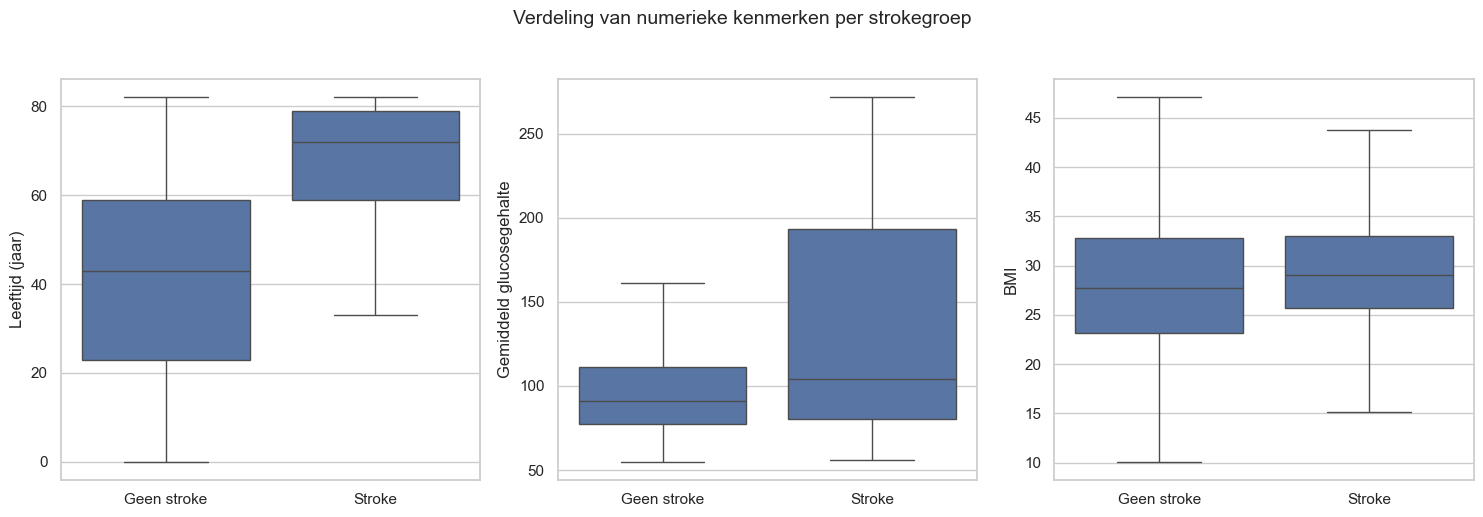

In [2]:

sns.set_theme(style="whitegrid", palette="deep")


numeriek = ["age", "avg_glucose_level", "bmi"]
labels = {
    "age": "Leeftijd (jaar)",
    "avg_glucose_level": "Gemiddeld glucosegehalte",
    "bmi": "BMI",
}
beschikbaar_numeriek = [kolom for kolom in numeriek if kolom in data.columns]

if beschikbaar_numeriek:
    fig, axes = plt.subplots(1, len(beschikbaar_numeriek), figsize=(5 * len(beschikbaar_numeriek), 5))
    if len(beschikbaar_numeriek) == 1:
        axes = [axes]

    for ax, kolom in zip(axes, beschikbaar_numeriek):
        sns.boxplot(data=data, x="stroke", y=kolom, ax=ax, showfliers=False)
        ax.set_xticks([0, 1])
        ax.set_xticklabels(["Geen stroke", "Stroke"])
        ax.set_xlabel("")
        ax.set_ylabel(labels[kolom])

    fig.suptitle("Verdeling van numerieke kenmerken per strokegroep", y=1.03, fontsize=14)
    plt.tight_layout()
    plt.show()

##### Waarom is gekozen voor boxplots?
Leeftijd, gemiddeld glucosegehalte en BMI zijn numerieke, continue kenmerken. Een boxplot is geschikt om zulke waarden tussen twee groepen te vergelijken: personen zonder stroke en personen met een stroke. In één compacte grafiek toont een boxplot zowel het centrale niveau als de spreiding van de waarden. Daardoor is niet alleen zichtbaar of één groep gemiddeld hoger of lager ligt, maar ook hoeveel de waarden binnen beide groepen overlappen.

##### Wat laat de boxplot zien?
De horizontale lijn in de box is de mediaan: de middelste waarneming wanneer alle waarden op volgorde staan. De onder- en bovenkant van de box zijn respectievelijk het eerste en derde kwartiel. De box bevat dus de middelste 50% van de personen. De lijnen buiten de box (de ‘snorren’) geven de gebruikelijke spreiding buiten dat middelste gebied weer. In deze code zijn uitschieters niet afzonderlijk getoond (showfliers=False). Dit houdt de figuur overzichtelijk, vooral wanneer een kenmerk zoals glucose enkele zeer hoge waarden bevat. De uitschieters blijven wel in de berekening van de boxplot; ze worden alleen niet als losse punten weergegeven.

##### Wat valt op en welke conclusie past daarbij?
Bij leeftijd ligt de box van de strokegroep duidelijk hoger dan die van de groep zonder stroke. Ook de mediaan ligt hoger. Dit wijst op een sterk beschrijvend verband: in deze dataset komen strokes vooral voor bij oudere personen. Leeftijd is daarom een belangrijk kenmerk om mee te nemen in verdere analyses.

Bij gemiddeld glucosegehalte ligt de verdeling van de strokegroep doorgaans hoger. Tegelijkertijd is de spreiding groot en overlappen de boxen deels. Een hoger glucosegehalte lijkt dus samen te hangen met een hoger strokepercentage, maar glucose alleen onderscheidt de groepen niet volledig.

Bij BMI overlappen de boxen meestal sterk. Als de medianen dicht bij elkaar liggen, is er op basis van deze figuur geen groot zelfstandig verschil tussen de twee groepen zichtbaar. Dat sluit een effect van BMI niet uit: een mogelijk verband kan kleiner zijn, beïnvloed worden door leeftijd of andere risicofactoren, of pas zichtbaar worden in een multivariaat model.

##### Waarom past deze visualisatie bij deze gegevens?
De uitkomstvariabele stroke bestaat uit twee groepen (0 en 1), terwijl de drie onderzochte kenmerken numeriek zijn. Boxplots zijn precies bedoeld voor deze combinatie: een numerieke verdeling per categorie vergelijken. Ze zijn bovendien robuuster dan alleen een gemiddelde, omdat de mediaan minder gevoelig is voor extreem hoge of lage waarden.

#### 1.6.2 Binaire medische kenmerken

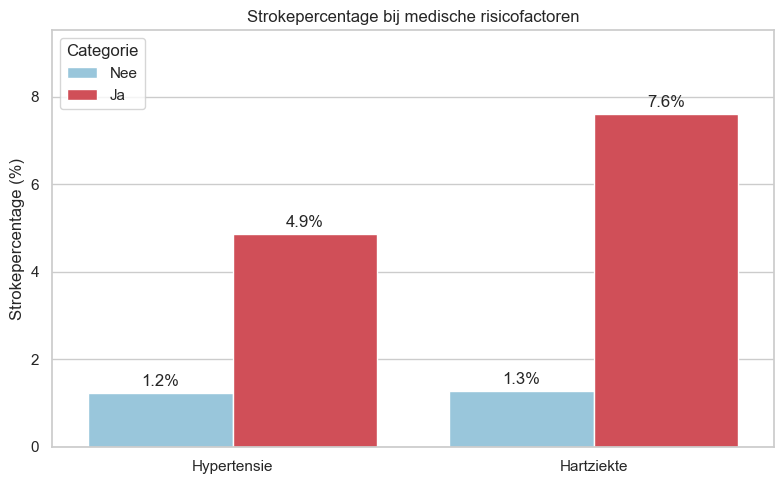

In [3]:

binair = ["hypertension", "heart_disease"]
mooie_binaire_namen = {
    "hypertension": "Hypertensie",
    "heart_disease": "Hartziekte",
}
rijen = []

for kolom in binair:
    if kolom not in data.columns:
        continue
    percentages = data.groupby(kolom)["stroke"].mean().mul(100)
    for waarde, percentage in percentages.items():
        rijen.append({
            "Kenmerk": mooie_binaire_namen[kolom],
            "Categorie": "Ja" if waarde == 1 else "Nee",
            "Strokepercentage": percentage,
        })

plotdata_binair = pd.DataFrame(rijen)
if not plotdata_binair.empty:
    plt.figure(figsize=(8, 5))
    ax = sns.barplot(
        data=plotdata_binair,
        x="Kenmerk",
        y="Strokepercentage",
        hue="Categorie",
        hue_order=["Nee", "Ja"],
        palette=["#8ecae6","#e63946"],
    )
    ax.set(
        title="Strokepercentage bij medische risicofactoren",
        xlabel="",
        ylabel="Strokepercentage (%)",
    )
    for container in ax.containers:
        ax.bar_label(container, fmt="%.1f%%", padding=3)
    plt.ylim(0, plotdata_binair["Strokepercentage"].max() * 1.25)
    plt.tight_layout()
    plt.show()


##### Waarom is gekozen voor een verticale balkgrafiek?
hypertension en heart_disease zijn binaire kenmerken: iemand heeft de aandoening wel (Ja) of niet (Nee). Voor dergelijke categorieën is het logisch om per categorie het strokepercentage te berekenen en als balk weer te geven. Een gegroepeerde balkgrafiek maakt het verschil tussen Ja en Nee binnen elk medisch kenmerk direct afleesbaar.

##### Wat laat de visualisatie zien?
Elke balk geeft het aandeel personen met een stroke binnen die specifieke groep weer. De percentages worden berekend als het gemiddelde van de binaire kolom stroke binnen elke categorie, vermenigvuldigd met 100. Een rode balk bij bijvoorbeeld Hartziekte, Ja toont dus: van alle personen met hartziekte, welk percentage heeft een stroke gehad? De labels op de balken maken de precieze percentages zichtbaar, zodat de lezer niet alleen visueel maar ook numeriek kan vergelijken.

##### Wat valt op en welke conclusie past daarbij?
De balken voor Ja zijn bij hypertensie en hartziekte hoger dan die voor Nee. Personen met deze medische risicofactoren hebben in deze dataset dus relatief vaker een stroke. Als het verschil bij hartziekte het grootst is, is hartziekte in de beschrijvende analyse de sterkste van deze twee signalen.

De juiste conclusie is dat beide kenmerken samenhangen met een hoger strokepercentage. De grafiek bewijst niet dat hypertensie of hartziekte op zichzelf de oorzaak is van de stroke. Personen met deze aandoeningen zijn bijvoorbeeld mogelijk ook gemiddeld ouder. Bovendien zegt de grafiek niets over de onzekerheid rond de percentages of over de omvang van de groepen. Rapporteer daarom bij een definitieve analyse ook de groepsgroottes en toets de verbanden in een multivariaat model.

##### Waarom past deze visualisatie bij deze gegevens?
De variabelen bestaan uit slechts twee duidelijke categorieën en de uitkomst is eveneens binair. Percentages per groep zijn daardoor goed interpreteerbaar. Een balkgrafiek communiceert dit sneller dan een tabel, terwijl de absolute schaal op de y-as eerlijke vergelijking van de verschillen mogelijk maakt.

#### 1.6.3 Categorische kenmerken

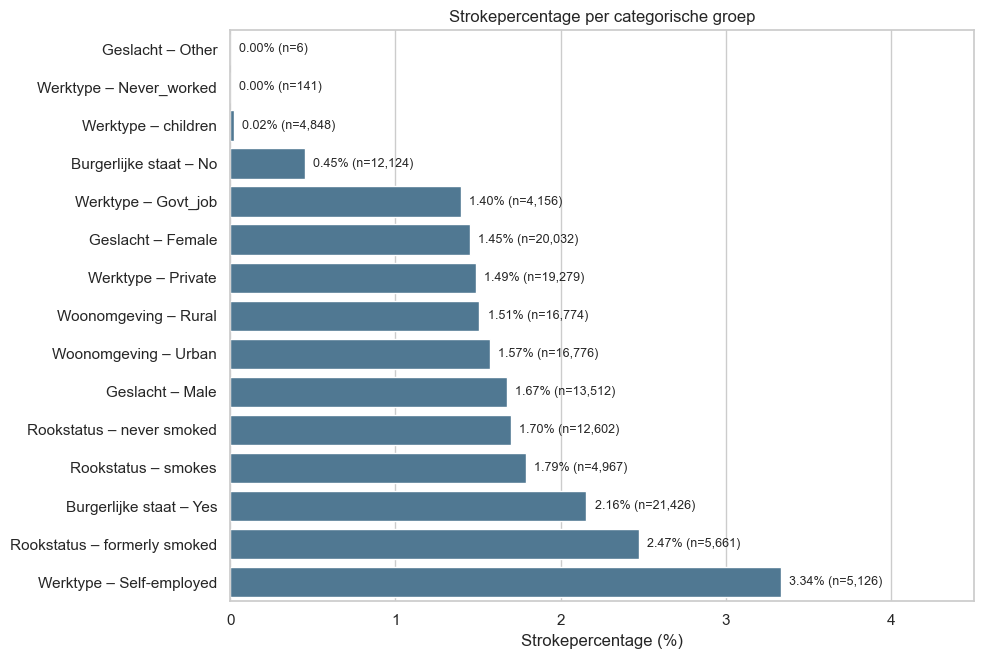

In [4]:
categorisch = {
    "gender": "Geslacht",
    "ever_married": "Burgerlijke staat",
    "work_type": "Werktype",
    "Residence_type": "Woonomgeving",
    "smoking_status": "Rookstatus",
}
rijen = []

# Ondersteunt zowel originele categorische kolommen als dummy-/one-hotkolommen.
for basis_kolom, mooie_naam in categorisch.items():
    if basis_kolom in data.columns:
        samenvatting = data.groupby(basis_kolom, dropna=False)["stroke"].agg(["count", "mean"]).reset_index()
        for _, rij in samenvatting.iterrows():
            categorie = "Onbekend" if pd.isna(rij[basis_kolom]) else str(rij[basis_kolom])
            rijen.append({
                "Kenmerk": mooie_naam,
                "Categorie": categorie,
                "Aantal": int(rij["count"]),
                "Strokepercentage": rij["mean"] * 100,
            })
    else:
        dummy_kolommen = [kolom for kolom in data.columns if kolom.startswith(f"{basis_kolom}_")]
        for dummy in dummy_kolommen:
            categorie = dummy[len(basis_kolom) + 1:]
            subset = data.loc[data[dummy] == 1, "stroke"]
            if not subset.empty:
                rijen.append({
                    "Kenmerk": mooie_naam,
                    "Categorie": categorie,
                    "Aantal": int(subset.count()),
                    "Strokepercentage": subset.mean() * 100,
                })

plotdata_cat = pd.DataFrame(rijen)
if not plotdata_cat.empty:
    plotdata_cat["Label"] = plotdata_cat["Kenmerk"] + " – " + plotdata_cat["Categorie"]
    plotdata_cat = plotdata_cat.sort_values("Strokepercentage")

    plt.figure(figsize=(10, max(6, len(plotdata_cat) * 0.45)))
    ax = sns.barplot(data=plotdata_cat, x="Strokepercentage", y="Label", color="#457b9d")
    ax.set(
        title="Strokepercentage per categorische groep",
        xlabel="Strokepercentage (%)",
        ylabel="",
    )

    for i, (_, rij) in enumerate(plotdata_cat.iterrows()):
        ax.text(
            rij["Strokepercentage"] + 0.05,
            i,
            f'{rij["Strokepercentage"]:.2f}% (n={rij["Aantal"]:,})',
            va="center",
            fontsize=9,
        )

    plt.xlim(0, plotdata_cat["Strokepercentage"].max() * 1.35)
    plt.tight_layout()
    plt.show()


##### Waarom is gekozen voor een horizontale balkgrafiek?
De kenmerken geslacht, burgerlijke staat, werktype, woonomgeving en rookstatus bestaan uit meerdere categorieën. Een horizontale balkgrafiek is hiervoor geschikt, omdat categorienamen zoals formerly smoked of Self-employed relatief lang kunnen zijn. Horizontale labels blijven leesbaar en alle groepen kunnen in één overzicht worden vergeleken. Door de balken te sorteren van laag naar hoog ontstaat bovendien direct een rangorde in strokepercentage.

##### Wat laat de visualisatie zien?
Elke balk is één categorie binnen één kenmerk. De lengte van de balk is het percentage strokes binnen die categorie. Het label aan het einde van de balk bevat daarnaast het percentage én de groepsgrootte (n). Daardoor is niet alleen te zien welke categorieën hoog of laag scoren, maar ook hoeveel waarnemingen achter dat percentage zitten.

Bijvoorbeeld: een hoog percentage bij work_type_Self-employed betekent dat binnen de groep zelfstandigen een relatief groot deel een stroke heeft. Een zeer laag percentage bij children betekent dat in de groep kinderen vrijwel geen strokes voorkomen. Dit is inhoudelijk plausibel, maar hangt zeer waarschijnlijk sterk samen met leeftijd: kinderen zijn veel jonger dan de overige groepen.

##### Wat valt op en welke conclusie past daarbij?
Categorieën zoals zelfstandigen en voormalige rokers kunnen relatief hoge strokepercentages laten zien. Groepen zoals children, Unknown en ever_married_No hebben vaak lage percentages. Deze verschillen mogen niet geïsoleerd worden geïnterpreteerd. Ze kunnen grotendeels het gevolg zijn van verschillen in leeftijd, gezondheid of andere kenmerken tussen de groepen. Zo zijn voormalige rokers vaak ouder dan nooit-rokers, en personen die nooit getrouwd zijn of kinderen zijn gemiddeld vaak jonger.

Ook de groepsgrootte is essentieel. Een hoog of laag percentage in een kleine categorie is instabieler dan hetzelfde percentage in een grote categorie. Daarom zijn gender_Other (n = 6) en work_type_Never_worked (n = 141) te klein voor betrouwbare, zelfstandige conclusies. Eén of enkele extra strokegevallen kunnen het percentage in zo’n kleine groep sterk veranderen.

##### Waarom past deze visualisatie bij deze gegevens?
De verklarende variabelen zijn nominaal: de categorieën hebben geen natuurlijke numerieke schaal. Het gemiddelde van stroke binnen iedere categorie is wel betekenisvol, omdat stroke 0 of 1 is; dit gemiddelde is precies het strokepercentage. De balkgrafiek zet die percentages overzichtelijk naast elkaar en is daardoor geschikt voor een eerste, beschrijvende verkenning.


### 1.7 Belangrijkste bevindingen




1. De data is schoon: geen missende waarden, dubbele rijen of dubbele identifiers. Na het verwijderen van `id` is de data technisch geschikt voor Scikit-Learn.


2. De target is **extreem ongebalanceerd**: slechts 1,54% van de patiënten heeft een stroke. Een gestratificeerde validatiestrategie, F1-score en technieken zoals klasseweging of resampling binnen trainingsfolds wordt toegepast in de portfolio.


3. **Leeftijd** is het duidelijkste individuele signaal. De groep met stroke is gemiddeld aanzienlijk ouder.



4. **Hartziekte** en **hypertensie** hebben sterke bivariate associaties met stroke; het strokepercentage is respectievelijk 7,62% en 4,87% in de positieve groepen.



5. Een hoger **gemiddeld glucosegehalte** komt vaker voor bij stroke. **BMI** laat daarentegen slechts een zwak verschil zien.



6. Rookstatus, burgerlijke staat en werktype laten verschillen zien, maar deze hangen waarschijnlijk deels samen met leeftijd. Modellen met meerdere features en controleer prestaties via cross-validatie worden daarom gebruikt.




7. De hoge glucose- en BMI-waarden zijn volgens de IQR-regel potentiële uitschieters. Ze zijn medisch plausibel en moeten niet automatisch worden verwijderd.

### 1.8 Opschonen

### Kolommen

Het model moet gefit worden op data die zo schoon mogelijk is. De features behoren geen ruis te geven. Daarom kijken we naar twee onderdelen

- Onmogelijke correlatie

Sommige informatie kan onmogelijk correleren, of zou niet moeten correleren met de predictor. In dit geval is het de ID kolom. Dit zijn willekeurige cijfers om elke rij te identificeren, alleen het model zal hier patronen proberen te ontdekken die niet bestaan, dit noem je ruis. Om deze reden zullen we de ID kolom weghalen



- Multicolineariteit

Kolommen die naar dummys worden omgezet hebben standaard een sterke correlatie met elkaar --> als het ene waar is, is het andere niet waar --> sterke negatieve correlatie. Dit zorgt ervoor dat de dummykolomen een sterkere weging krijgen zonder dat dat de bedoeling is. We kunnen dit voorkomen door per onderscheiding één klasse weg te halen, waardoor de ontbrekende klasse van toepassing is als de overige 'False' geven. Hieronder is een overzicht gemaakt van de klassen per variabele.




| Variabele | Categorieën |
|---|---|
| **Gender** | `gender_male`, `gender_female`, `gender_other` |
| **ever_married** | `ever_married_No`, `ever_married_Yes` |
| **work_type** | `Govt_job`, `Never_worked`, `Private`, `Self-employed`, `children` |
| **Residence_type** | `Rural`, `Urban` |
| **smoking_status** | `formerly_smoked`, `never_smoked`, `smokes`, `unknown` |


Bij de beschrijving van de opdracht is er aangegeven dat smoking_status al een verwijderde kolom heeft. Daarom hoeft deze variabele niet aangepast te worden.

In [5]:
dropcols = ['id', 'gender_Male', 'ever_married_No', 'work_type_Govt_job', 'Residence_type_Rural']

### Rijen

Om irrelevante rijen te verwijderen kijken we weer naar twee onderdelen

- Missende waarden door geen datagerelateerde reden --> MCAR

De dataset bevat geen missende waarden, dus hier hoeft niks aan te gebeuren.


- Onmogelijke/foute waarden

Hierbij kijken we of er extreem hoge/lage waarden zijn.

Zoals je hieronder kunt zien zijn alle histplots redelijk normaal. Er zijn geen extreme (onrealistische) uitschieters met onmogelijke waarden. 

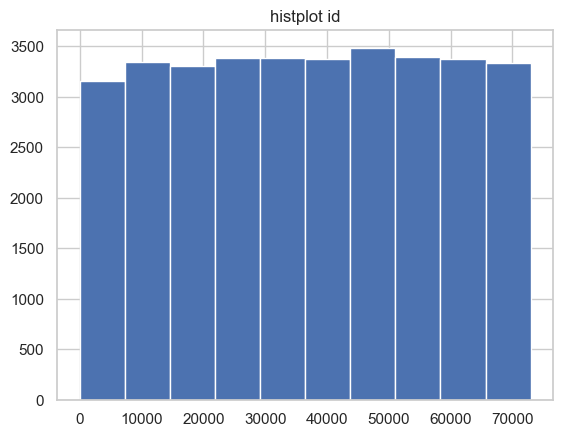

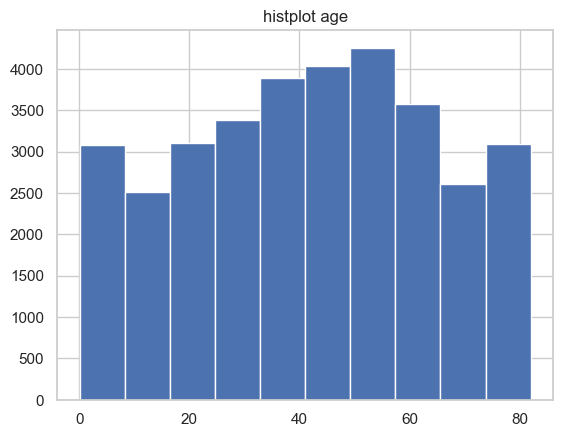

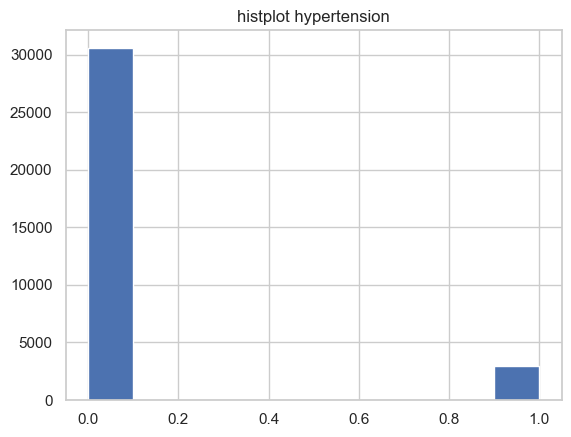

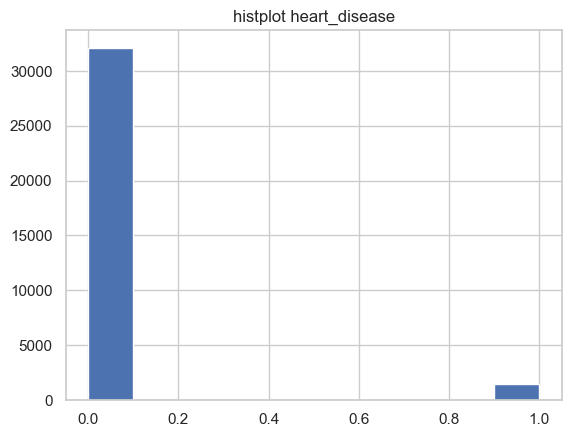

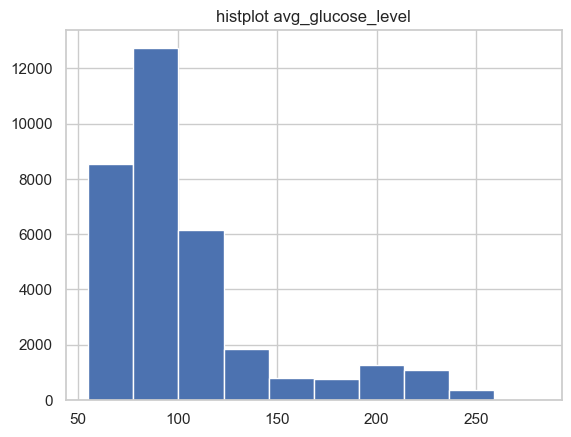

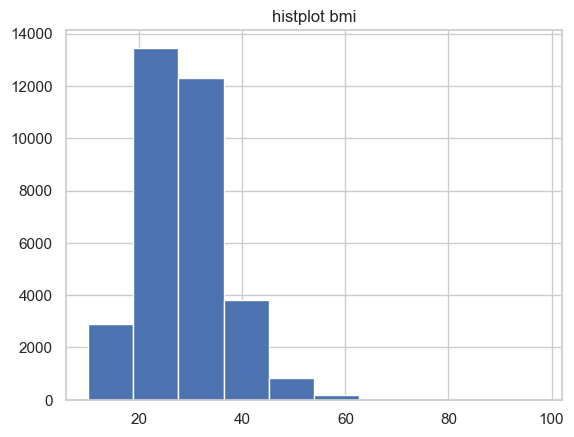

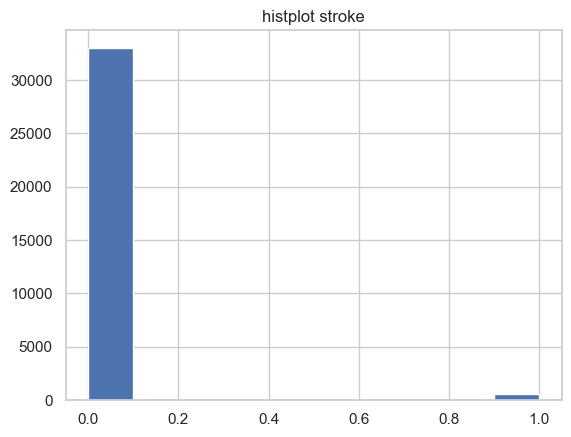

In [6]:
for i in data.select_dtypes(include=["integer", "floating"]).columns:
    plt.hist(data[i])
    plt.title(f"histplot {i}")
    plt.show()

Definitieve opschoning:

In [7]:
df = data.drop(dropcols, axis=1)

### 1.6 Standaardiseren

- Wat is standaardiseren?

Door data te standaardiseren, breng je features op een vergelijkbare schaal door ze zo te transformeren dat het gemiddelde 0 is en de standaarddeviatie 1. 

- Waarom zou je willen standaardiseren?

Het is gewenst om te standaardiseren als je data bestaat uit verschillende schalen. ML modellen die afstanden of coefficienten gebruiken zoals Logistische Regressie, Support Vector Machine of KNN, kunnen grotere getallen onnodig zwaardere wegingen geven, dit kan dus leiden tot overfitting.

### Uitvoering/definiering standaardisatie

standaardisatie moet per split worden uitgevoerd pas nadat de data is gesplitst om data-lekkage te voorkomen. Daarom zal nu hier een functie worden aangemaakt die later standaardisatie zal uitvoeren na het splitsen van de data. Ook zal er meteen een functie worden gemaakt om alle kolommen nummeriek te maken.

In [8]:
def bool_to_num(dataframe):

    """ 
    Maak boolean kolommen nummeriek.
    Geef data set terug met omgezette kolommen.
    """

    for i in dataframe.select_dtypes(include='bool').columns:
        dataframe[i] = dataframe[i].astype(int)

    return dataframe

    


def standardiseer(X_train, X_test):

    """
    Standaardiseer X_train en X_test individueel
    Geef twee datasets terug met gestandaardiseerde waarden.
    """

    scaler = StandardScaler()
    train = scaler.fit_transform(X_train) #Gemiddelde en standaarddeviatie wordt berekend op traindata
    test = scaler.transform(X_test)       #Gemiddelde en standaarddeviatie wordt overgenomen van traindata --> geen data-lekkage

    return train, test


-----

## 2. Evaluatie



In dit hoofdstuk bepalen we met welke metrics kan worden gemeten hoe goed een model presteert op het stroke-voorspellingsprobleem. We demonstreren deze metrics aan de hand van een K-Nearest Neighbors (KNN) model.

### 2.1 Welke metrics zijn relevant?

We voorspellen of iemand een herseninfarct krijgt (ja/nee). Dit is dus een **binaire classificatie**. Bovendien is de dataset **imbalanced**: er zijn veel meer patiënten zonder stroke dan met stroke. Dit heeft grote gevolgen voor welke metrics zinvol zijn.

#### Confusion Matrix als basis

Alle metrics komen voort uit vier basiswaarden:

|  | **Voorspeld: Geen stroke** | **Voorspeld: Stroke** |
|---|---|---|
| **Werkelijk: Geen stroke** | True Negative (TN) | False Positive (FP) |
| **Werkelijk: Stroke** | False Negative (FN)  | True Positive (TP) |

In een **medische context** is een **False Negative (gemiste stroke) veel erger** dan een False Positive (vals alarm). Een gemiste stroke betekent dat een patiënt met verhoogd risico geen preventieve zorg krijgt.

#### De belangrijkste metrics

**Accuracy**
Het percentage patiënten dat correct voorspeld is. Deze metric is **misleidend bij imbalanced data**: een model dat altijd "geen stroke" voorspelt, haalt al rond de 95% accuracy, maar is in de praktijk waardeloos omdat het geen enkele stroke-patiënt herkent.

**Precision**
Van alle patiënten die het model als "stroke" bestempelt, hoeveel hebben er écht een stroke? Een hoge precision betekent weinig vals alarm.

**Recall (Sensitivity)**
Van alle werkelijke stroke-patiënten, hoeveel vangt het model er op? Deze metric is **zeer belangrijk in deze medische context**, omdat we zo min mogelijk patiënten willen missen.

**F1-score**
Het harmonisch gemiddelde van precision en recall. Deze metric is pas hoog als zowel precision als recall hoog zijn. **Dit is de officiële Kaggle-metric** voor deze competitie.

**ROC-AUC**
De oppervlakte onder de ROC-curve. Deze waarde ligt tussen 0.5 (random gokken) en 1.0 (perfect model). Nuttig om modellen onderling te vergelijken, onafhankelijk van de gekozen drempelwaarde.

**Specificity**
Van alle gezonde mensen, hoeveel worden correct als "geen stroke" aangemerkt? Complementair aan recall.

### 2.2 Waarom F1-score de beste maatstaf is voor dit vraagstuk

In de Kaggle-competitie wordt gekozen voor de F1-score om modellen te beoordelen. Dit is om de volgende redenen de meest geschikte maatstaf:

1. **Accuracy faalt bij imbalanced data.** Omdat ongeveer 95% van de patiënten geen stroke heeft, haalt een model dat niemand als stroke-patiënt classificeert al een zeer hoge accuracy, zonder dat het model enige waarde heeft.
2. **Alleen Precision is niet genoeg.** Dit zou een model belonen dat zelden "stroke" voorspelt (hoge zekerheid), maar daardoor veel patiënten mist.
3. **Alleen Recall is ook niet genoeg.** Dit zou een model belonen dat iedereen als stroke bestempelt (geen gemiste patiënten), maar dat veroorzaakt enorm veel vals alarm.
4. **F1-score dwingt een balans af** tussen precision en recall. Een model moet zowel weinig patiënten missen (recall) als nauwkeurig zijn in zijn positieve voorspellingen (precision) om een goede score te halen.
5. In een medische toepassing is dit een redelijke keuze. In een echte productieomgeving zou men mogelijk nog meer gewicht aan recall willen geven (bijvoorbeeld via de F2-score), omdat een gemiste stroke ernstigere gevolgen heeft dan een vals alarm.

### 2.3 Demonstratie met K-Nearest Neighbors

Hieronder trainen we een eenvoudig KNN-model en berekenen we alle bovenstaande metrics om te laten zien hoe deze zich tot elkaar verhouden op dit probleem.


In [9]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report
import pandas as pd

train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")
y = train["stroke"]
X = train.drop(["stroke", "id"], axis=1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,      
    random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_scaled, y_train)
y_pred = knn.predict(X_test_scaled)

print(f"Nauwkeurigheid: {accuracy_score(y_test, y_pred):.2%}")
print(classification_report(y_test, y_pred))

Nauwkeurigheid: 98.33%
              precision    recall  f1-score   support

           0       0.98      1.00      0.99      6600
           1       0.00      0.00      0.00       110

    accuracy                           0.98      6710
   macro avg       0.49      0.50      0.50      6710
weighted avg       0.97      0.98      0.98      6710



---

# 3 Modelleren en uitleg modellen

## Train/Val Datasets

De data wordt omgezet in train en validatiesets.

In [10]:
df_stroke = bool_to_num(df) 



X = df_stroke.drop('stroke', axis=1) 
y = df_stroke['stroke']


X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, random_state=42)
X_train, X_val = standardiseer(X_train, X_val)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42) #gebruik deze cross validation bij hyperparameter tunen

Datasets voor submission

In [11]:
test_df = pd.read_csv('test.csv')
test_ids = test_df['id']          # id's bewaren voordat je kolommen dropt

X_test_final = bool_to_num(test_df).drop(dropcols, axis=1)

#Fit je model hierop voor het submitten
X_train_final = df_stroke.drop('stroke', axis=1) 
y_train_final = df_stroke['stroke']

X_train_final, X_test_final = standardiseer(X_train_final, X_test_final)

threshold finder, werkt niet voor SVM

In [12]:
def threshold_finder(model, X_val, y_val):

    """
    Gebruikt model en validatiedata om de beste threshold te berekenen voor de hoogste f1 score
    Geeft beste threshold terug
    """

    proba = model.predict_proba(X_val)[:, 1]
    precision, recall, thresholds = precision_recall_curve(y_val, proba)
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)

    idx = np.argmax(f1)
    
    

    return thresholds[idx]

# Modellen

## 3.x Model (template)

Standaard model -- geen toevoegingen

In [13]:
#fit model --> trainset
#maak confusionmatrix en classification report --> validatieset


Hyperparameters tunen met cross validation, daarna validatietest

In [14]:
#pas een hyperparameter tuning model naar keuze toe --> gebruik de trainset
#gebruik gedefinieerde variabele 'cv' als cross validation --> cv=cv


In [15]:
#fit model met hyperparameters opnieuw
#maak confusionmatrix en classification report --> validatieset

Beste threshold vinden, daarna test      (dit geeft meestal betere resultaten)

In [16]:
#gebruik threshold_finder() met nieuwe model, en X_val, y_val

Kaggle submit

In [17]:
#fit op final train en test, maak csv
#kijk voor voorbeeld bij Random Forest (zonder threshold) en Gradient Boosted Trees (met threshold)

## KNN

### Theorie

#### Hoe werkt het model?

K-Nearest Neighbors is een **instance-based** classificatie-algoritme. In plaats van tijdens het trainen een wiskundig model te leren, slaat KNN simpelweg de volledige trainingsset op. Pas op het moment dat er een nieuw datapunt moet worden voorspeld, gaat het model aan de slag:

1. Het berekent de **afstand** tussen het nieuwe datapunt en élk punt uit de trainingsset.
2. Het selecteert de **k dichtstbijzijnde buren** (vandaar de naam).
3. Het laat deze buren "stemmen": de klasse die het vaakst voorkomt onder de k buren wordt de voorspelling (majority vote).

#### Afstandsmaten

Hoe die "afstand" wordt berekend hangt af van de gekozen afstandsmaat. De twee meest gebruikte zijn:

- **Euclidean afstand**: de rechte lijn tussen twee punten in de ruimte (de "hemelsbrede" afstand). Dit is de standaard in scikit-learn en werkt goed als features op een vergelijkbare schaal staan en continu zijn.
- **Manhattan afstand**: de som van de absolute verschillen per dimensie (vergelijkbaar met hoe je door een stratenblok loopt in Manhattan). Deze is minder gevoelig voor uitschieters en werkt vaak beter in hogere dimensies.

De keuze tussen Euclidean en Manhattan is één van de hyperparameters die we tijdens de tuning gaan testen.

#### Waarom schalen we bij KNN?

Afstanden tussen punten zijn bepalend voor welke groep het model kiest om nieuwe datapunten aan toe te voegen, en daarom is het van groot belang dat alle features geschaald worden naar een universele schaal. Anders raakt het model in de war tijdens het fitten van alle grote en kleine waardes door elkaar heen.

Een feature als `avg_glucose_level` (waardes tot ~270) zou anders de afstandsberekening volledig domineren over een feature als `hypertension` (waardes 0 of 1), waardoor die laatste praktisch genegeerd wordt. Door te standaardiseren met **StandardScaler** krijgen alle features een gemiddelde van 0 en een standaarddeviatie van 1, zodat ze allemaal evenveel gewicht krijgen in de afstandsberekening.

#### Hoe wordt regularisatie toegepast?

Het doel van regularisatie is dat we overfitting tegen willen gaan en dit gebeurt door ten eerste een juiste k te kiezen. Bij een te lage k wordt het model te complex en is heel gevoelig voor uitschieters. Bij een te hoge k wordt het model te algemeen. Het doel is dus om de balans tussen beiden te vinden. Ook wordt er geregulariseerd door gewogen buren. Dit betekent dat buren die dichterbij het nieuwe datapunt liggen zwaarder meewegen.

#### Hyperparameter tuning

Met behulp van **GridSearchCV** (5-fold cross-validation, scoring op F1) zoeken we de beste combinatie van onderstaande hyperparameters:

| Hyperparameter | Geteste waarden | Wat het doet |
|---|---|---|
| `n_neighbors` (k) | 3, 5, 7, 9, 11, 15, 21 | Aantal buren dat meestemt |
| `weights` | `uniform`, `distance` | Alle buren gelijk vs. dichtere buren zwaarder |
| `metric` | `euclidean`, `manhattan` | Welke afstandsmaat wordt gebruikt |
| `p` | 1, 2 | Parameter van Minkowski-afstand (1 = Manhattan, 2 = Euclidean) |

Omdat de dataset imbalanced is, gebruiken we **F1-score** als scoring-metric tijdens het tunen (en niet accuracy). De beste gevonden combinatie passen we toe op de volledige trainingsset en evalueren we op de test-set en op Kaggle.

#### Omgaan met class imbalance

De dataset bevat veel meer "geen stroke" dan "stroke" patiënten. KNN heeft hier extra last van: als er bij een punt vrijwel alleen "geen stroke"-buren in de buurt liggen, zal het model bijna nooit "stroke" voorspellen. We passen daarom twee technieken toe:

**1. SMOTE (Synthetic Minority Oversampling Technique)**
SMOTE creëert nieuwe, synthetische stroke-patiënten door te interpoleren tussen bestaande stroke-patiënten en hun dichtstbijzijnde buren uit dezelfde minderheidsklasse. Zo wordt de trainingsset gebalanceerd zónder dat we echte data verwijderen. Belangrijk: SMOTE wordt **alleen op de trainingsset** toegepast, nooit op de test-set, om data leakage te voorkomen.

**2. Gewogen buren (`weights='distance'`)**
Door buren die dichter bij het nieuwe punt liggen zwaarder te laten meewegen, krijgen zeldzame stroke-patiënten in de directe omgeving van een testpunt relatief meer invloed dan verre "geen stroke"-buren. Dit helpt het model om de minderheidsklasse beter te herkennen zonder dat we de data zelf veranderen.


Gemiddelde F1 (cross-validation): 0.0000 (± 0.0000)

F1-score per waarde van k:
  k= 1  :  F1-score: 0.0385
  k= 3  :  F1-score: 0.0137
  k= 5  :  F1-score: 0.0000
  k=10  :  F1-score: 0.0000
  k=20  :  F1-score: 0.0000

Beste threshold voor F1: 0.100
F1-score op validatieset (met beste threshold): 0.0793
              precision    recall  f1-score   support

           0       0.99      0.88      0.93      8259
           1       0.04      0.35      0.08       129

    accuracy                           0.88      8388
   macro avg       0.52      0.62      0.51      8388
weighted avg       0.97      0.88      0.92      8388


Submission opgeslagen als 'submission_knn.csv' (1068 positieve voorspellingen van 8388 patiënten)


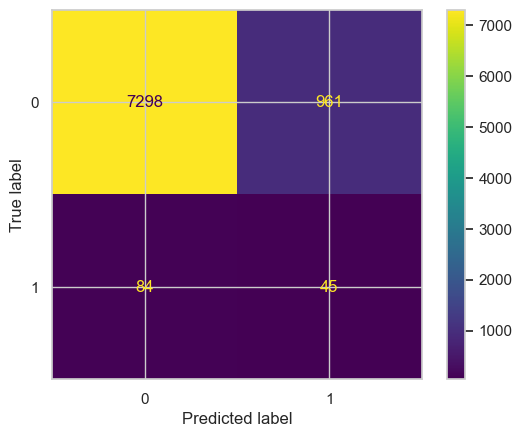

In [18]:

knn = KNeighborsClassifier(n_neighbors=10)
knn.fit(X_train, y_train)

# Cross-validation score (F1, want de dataset is imbalanced)
cv_scores = cross_val_score(knn, X_train, y_train, cv=cv, scoring='f1')
print(f"Gemiddelde F1 (cross-validation): {cv_scores.mean():.4f} "
      f"(± {cv_scores.std():.4f})")


# Voor de beste k hebben we een simpele for-loop gebruikt.
# We evalueren op F1-score (niet accuracy) omdat de dataset
# imbalanced is. Het maakt weinig verschil of we k=10 of k=20
# gebruiken, dus hier kiezen we voor k=10 als baseline.
# In de hyperparameter-tuning (hieronder) wordt dit verfijnd.

print("\nF1-score per waarde van k:")
for k in [1, 3, 5, 10, 20]:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    y_pred_k = model.predict(X_val)
    f1 = f1_score(y_val, y_pred_k)
    print(f"  k={k:2d}  :  F1-score: {f1:.4f}")

# Beste drempelwaarde vinden
best_threshold = threshold_finder(knn, X_val, y_val)
print(f"\nBeste threshold voor F1: {best_threshold:.3f}")

# Voorspellingen op validatieset met geoptimaliseerde threshold
y_val_proba = knn.predict_proba(X_val)[:, 1]
y_val_pred  = (y_val_proba >= best_threshold).astype(int)

print(f"F1-score op validatieset (met beste threshold): "
      f"{f1_score(y_val, y_val_pred):.4f}")

# Confusion matrix + rapport op validatieset
ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred)
print(classification_report(y_val, y_val_pred))

# Model opnieuw fitten op volledige trainingsdata voor Kaggle
knn_final = KNeighborsClassifier(n_neighbors=10)
knn_final.fit(X_train_final, y_train_final)

# Voorspellingen op de test-set (Kaggle)
test_proba = knn_final.predict_proba(X_test_final)[:, 1]
test_pred  = (test_proba >= best_threshold).astype(int)

# Submission-bestand aanmaken
submission = pd.DataFrame({
    'id': test_ids,
    'stroke': test_pred
})
submission.to_csv('submission_knn.csv', index=False)
print(f"\nSubmission opgeslagen als 'submission_knn.csv' "
      f"({submission['stroke'].sum()} positieve voorspellingen "
      f"van {len(submission)} patiënten)")

## Logistic Regression


### Theorie

#### Hoe werkt het model?

**Logistic Regression** is, ondanks de naam, een **classificatie-algoritme**. Het model is bedoeld om bij een rij features $x = (x_1, x_2, \dots, x_n)$ een **kans** te voorspellen dat die rij tot de positieve klasse behoort (in ons geval: *stroke = 1*). Het model doet dit in twee stappen: eerst een lineaire combinatie van de features, daarna een transformatie met de sigmoid-functie zodat de uitkomst tussen 0 en 1 ligt.

**Stap 1 — lineaire combinatie van de features**

Net als bij lineaire regressie berekent het model eerst een gewogen som van de features plus een bias-term:

$$
z = w_0 + w_1 x_1 + w_2 x_2 + \dots + w_n x_n = \mathbf{w}^\top \mathbf{x} + b
$$

In deze formule stelt $x_i$ de waarde van feature $i$ voor (bijvoorbeeld `age`, `avg_glucose_level` of `hypertension`). Het bijbehorende gewicht $w_i$ is de coëfficiënt die het model voor die feature heeft geleerd: een groot positief gewicht betekent dat de feature de kans op stroke verhoogt, terwijl een negatief gewicht die kans juist verlaagt. De term $b$ is de bias (intercept) en het eindresultaat $z$ noemen we de *logit*, een getal dat tussen $-\infty$ en $+\infty$ ligt.

**Stap 2 — sigmoid-functie om de logit om te zetten in een kans**

De logit $z$ wordt door de **sigmoid-functie** $\sigma(\cdot)$ geperst, zodat de uitkomst altijd tussen $0$ en $1$ ligt:

$$
\hat{y} = P(y=1 \mid \mathbf{x}) = \sigma(z) = \frac{1}{1 + e^{-z}}
$$

De uitkomst $\hat{y}$ is de voorspelde kans dat de patiënt een stroke heeft. Standaard wordt met een drempelwaarde (threshold) van $0{,}5$ beslist tot welke klasse de voorspelling behoort: bij $\hat{y} \geq 0{,}5$ voorspelt het model klasse $1$, anders klasse $0$. Omdat onze dataset sterk imbalanced is, gebruiken we net als bij de andere modellen `threshold_finder()` om een betere drempelwaarde voor de F1-score te zoeken.

**Waarom schalen we bij Logistic Regression?**

Logistic Regression leert de gewichten $w_i$ door een loss-functie te minimaliseren met gradient descent. Features met grote waarden (zoals `avg_glucose_level` met waarden tot ongeveer $280$) krijgen daardoor automatisch kleinere gewichten, terwijl features met kleine waarden (zoals `hypertension` met $0$ of $1$) juist grotere gewichten krijgen. Bovendien beïnvloedt de L1/L2-regularisatie (zie verder) alle gewichten op dezelfde schaal. Als de features op heel verschillende schalen staan, is dat oneerlijk: features met grote getallen worden harder "gestraft". We standaardiseren daarom met `StandardScaler`, net als bij KNN.

### Loss-functie: Binary Cross-Entropy (Log Loss)

Om de gewichten $\mathbf{w}$ en de bias $b$ te leren, moet het model weten hoe fout zijn voorspellingen zijn. Dit meten we met de **binary cross-entropy** (ook wel *log loss* genoemd):

$$
\mathcal{L}(\mathbf{w}, b) = -\frac{1}{m} \sum_{i=1}^{m} \Big[\, y_i \log(\hat{y}_i) + (1 - y_i)\log(1 - \hat{y}_i) \,\Big]
$$

Hierin is $m$ het aantal trainingsvoorbeelden, is $y_i \in \{0, 1\}$ de werkelijke klasse van patiënt $i$, en is $\hat{y}_i = \sigma(\mathbf{w}^\top \mathbf{x}_i + b)$ de voorspelde kans voor diezelfde patiënt.

**Intuïtie.** Voor een echte stroke-patiënt ($y_i = 1$) telt alleen de term $\log(\hat{y}_i)$ mee. Voorspelt het model een kans van bijna $1$, dan is $\log(\hat{y}_i)$ bijna $0$ en is de loss laag. Voorspelt het model juist een kans van bijna $0$, dan gaat $\log(\hat{y}_i)$ naar $-\infty$ en wordt de loss enorm groot. Voor een gezonde patiënt ($y_i = 0$) telt alleen $\log(1 - \hat{y}_i)$ mee en geldt precies hetzelfde idee, maar omgekeerd. De loss straft dus vooral **zelfverzekerde foute voorspellingen** zwaar af — precies wat je wilt bij een medisch probleem.

### Gradient Descent

#### Wat is gradient descent in deze context?


Er bestaat geen formule waarmee we $\mathbf{w}$ en $bdirect kunnen uitrekenen zoals bij lineaire regressie met de kleinste-kwadratenmethode. In plaats daarvan gebruikt scikit-learn een **iteratief optimalisatie-algoritme** om de loss te minimaliseren. Gradient descent is daarvan de bekendste vorm.

Het idee is simpel: begin met willekeurige (of nul-)gewichten en zet elke iteratie een kleine stap in de richting waarin de loss het snelst daalt. Die richting is de **negatieve gradient** van de loss. De update-regel voor elk gewicht $w_j$ en voor de bias $b$ luidt:

$$
w_j := w_j - \eta \cdot \frac{\partial \mathcal{L}}{\partial w_j}
\qquad\text{en}\qquad
b := b - \eta \cdot \frac{\partial \mathcal{L}}{\partial b}
$$

De factor $\eta$ heet de *learning rate* en bepaalt de stapgrootte. Voor logistic regression blijken de partiële afgeleiden mooi eenvoudig te zijn:

$$
\frac{\partial \mathcal{L}}{\partial w_j} = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}_i - y_i)\, x_{ij}
\qquad\text{en}\qquad
\frac{\partial \mathcal{L}}{\partial b} = \frac{1}{m} \sum_{i=1}^{m} (\hat{y}_i - y_i)
$$

In woorden: de fout $(\hat{y}_i - y_i)$ wordt vermenigvuldigd met de bijbehorende feature-waarde en gemiddeld over alle trainingsvoorbeelden.

#### Eenvoudig rekenvoorbeeld

Stel we hebben één feature (bijvoorbeeld de gestandaardiseerde leeftijd) en drie trainingsvoorbeelden:

| $i$ | $x_i$ | $y_i$ |
|---|---:|---:|
| 1 | $-1$ | $0$ |
| 2 | $\;\,0$ | $0$ |
| 3 | $\;\,1$ | $1$ |

We beginnen met $w = 0$ en $b = 0$, en kiezen een learning rate van $\eta = 1$.

**Forward pass.** Omdat $w = 0$ en $b = 0$ geldt voor elk voorbeeld $z_i = 0$ en dus $\hat{y}_i = \sigma(0) = 0{,}5$. De fouten $(\hat{y}_i - y_i)$ worden daarmee respectievelijk $0{,}5$, $0{,}5$ en $-0{,}5$.

**Gradient van $w$.** Invullen van de formule geeft:

$$
\frac{\partial \mathcal{L}}{\partial w} = \frac{1}{3}\big(0{,}5 \cdot (-1) + 0{,}5 \cdot 0 + (-0{,}5) \cdot 1\big) = \frac{-1}{3} \approx -0{,}333
$$

**Gradient van $b$.** Op dezelfde manier:

$$
\frac{\partial \mathcal{L}}{\partial b} = \frac{1}{3}\big(0{,}5 + 0{,}5 - 0{,}5\big) = \frac{0{,}5}{3} \approx 0{,}167
$$

**Update van de parameters.** Met $\eta = 1$ wordt het nieuwe gewicht $w := 0 - 1 \cdot (-0{,}333) = 0{,}333$ en de nieuwe bias $b := 0 - 1 \cdot 0{,}167 = -0{,}167$.

**Controle.** Voor voorbeeld 3 (de echte stroke-patiënt) krijgen we nu $z_3 = 0{,}333 \cdot 1 + (-0{,}167) = 0{,}166$ en dus $\hat{y}_3 = \sigma(0{,}166) \approx 0{,}541$. De voorspelde kans voor deze patiënt is dus gestegen van $0{,}5$ naar ongeveer $0{,}541$, precies wat we willen. Als we dit duizenden iteraties herhalen, convergeren de gewichten naar de combinatie die de totale log loss minimaliseert. Scikit-learn gebruikt onder de motorkap efficiëntere varianten (`lbfgs`, `liblinear`, `saga`), maar het onderliggende principe is hetzelfde.

### Regularisatie

Logistic Regression kan overfitten door **sommige gewichten extreem groot te laten worden**, vooral als er veel (gecorreleerde) features zijn. Regularisatie voegt een **strafterm** aan de loss toe die grote gewichten ontmoedigt. Scikit-learn ondersteunt vier varianten via de parameter `penalty`: L2, L1, Elastic Net en geen regularisatie.

#### 1. L2-regularisatie (`penalty='l2'`) — standaard

De L2-variant voegt het **kwadraat** van elk gewicht toe aan de loss:

$$
\mathcal{L}_{\text{L2}}(\mathbf{w}, b) = \mathcal{L}(\mathbf{w}, b) + \frac{1}{2C} \sum_{j=1}^{n} w_j^2
$$

Het effect is dat alle gewichten richting $0$ worden geduwd, maar vrijwel nooit precies $0$ worden. Het model blijft dus alle features gebruiken, maar met kleinere, stabielere coëfficiënten. L2 is bovendien sterk tegen multicollineariteit, wat handig is omdat onze dataset veel dummy-kolommen bevat. De hyperparameter $C$ in scikit-learn is de **inverse** van de regularisatiesterkte: een kleine $C$ geeft dus een sterke regularisatie, een grote $C$ een zwakke.

#### 2. L1-regularisatie (`penalty='l1'`)

De L1-variant straft de **absolute waarde** van elk gewicht:

$$
\mathcal{L}_{\text{L1}}(\mathbf{w}, b) = \mathcal{L}(\mathbf{w}, b) + \frac{1}{C} \sum_{j=1}^{n} |w_j|
$$

Het effect is dat sommige gewichten exact naar $0$ worden geduwd. L1 doet daarmee **automatisch feature-selectie**: minder relevante features vallen volledig weg. Dit is handig als je vermoedt dat sommige van de 20 features (bijvoorbeeld zeldzame dummy's zoals `work_type_Never_worked`) weinig toevoegen aan de voorspelling.

#### 3. Elastic Net (`penalty='elasticnet'`)

Elastic Net combineert L1 en L2 in één strafterm, gestuurd door de mengparameter $\rho$ (in scikit-learn: `l1_ratio`):

$$
\mathcal{L}_{\text{EN}}(\mathbf{w}, b) = \mathcal{L}(\mathbf{w}, b) + \frac{1}{C}\left(\rho \sum_j |w_j| + \frac{1 - \rho}{2}\sum_j w_j^2\right)
$$

Bij $\rho = 0$ krijg je puur L2, bij $\rho = 1$ puur L1, en daartussen een mengvorm. Het effect is dat je zowel de **feature-selectie van L1** als de **stabiliteit van L2** krijgt. In scikit-learn werkt Elastic Net alleen in combinatie met de solver `saga`.

#### 4. Geen regularisatie (`penalty=None`)


Zonder strafterm wordt gewoon de pure log loss geminimaliseerd:

$$
\mathcal{L}_{\text{None}}(\mathbf{w}, b) = \mathcal{L}(\mathbf{w}, b)
$$

Deze variant geeft een grote kans op overfitting als het aantal features groot is of als features onderling gecorreleerd zijn. In de praktijk dient `penalty=None` vooral als vergelijkingsbaseline om te zien hoeveel de regularisatie werkelijk toevoegt.

### Hoe verhoudt regularisatie zich tot overfitting?


**Overfitting** betekent dat het model de **ruis** in de trainingsdata uit zijn hoofd leert: het presteert bijna perfect op de training set maar slecht op nieuwe (validatie-)data. Bij Logistic Regression ontstaat dit vooral doordat sommige gewichten extreem groot worden om zelfs individuele trainingsvoorbeelden perfect te kunnen voorspellen.

Regularisatie werkt als een tegenkracht: de strafterm maakt grote gewichten letterlijk duur in de loss. Het model wordt daardoor gedwongen om alleen gewichten groot te maken als dat écht een duidelijke verlaging van de log loss oplevert. Een te sterke regularisatie (kleine $C$) houdt alle gewichten dicht bij $0$, waardoor het model te simpel wordt en gaat **underfitten**. Een te zwakke regularisatie (grote $C$ of `penalty=None`) geeft de gewichten vrij spel en leidt juist tot **overfitting**. Pas met een goed afgestemde regularisatie leert het model alleen de echte, generaliseerbare patronen en behaalt het de beste F1-score op validatie- en testset. De juiste hoeveelheid regularisatie — dus de combinatie van $C$, `penalty` en bij Elastic Net ook $\rho$ — vinden we net als bij de andere modellen via **cross-validation**.

### Hyperparameter tuning

De officiële [scikit-learn documentatie van `LogisticRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html) beschrijft welke solvers welke `penalty`-waarden ondersteunen. Hierop baseren we het grid:

| Solver | Ondersteunde penalties |
|---|---|
| `lbfgs` *(default)* | `l2`, `None` |
| `liblinear` | `l1`, `l2` |
| `saga` | `l1`, `l2`, `elasticnet`, `None` |
| `newton-cg`, `newton-cholesky`, `sag` | `l2`, `None` |

We tunen daarom via **GridSearchCV** met dezelfde `cv` (`RepeatedStratifiedKFold`) en scoring (`f1`) als bij de andere modellen:

| Hyperparameter | Geteste waarden | Wat het doet |
|---|---|---|
| `penalty` | `l1`, `l2`, `elasticnet`, `None` | Type regularisatie |
| `C` | `0.01, 0.1, 1, 10, 100` | **Inverse** van regularisatiesterkte — kleiner = sterker |
| `solver` | `liblinear`, `lbfgs`, `saga` | Optimalisatie-algoritme |
| `l1_ratio` | `0.2, 0.5, 0.8` | Mengverhouding L1/L2 (alleen voor elastic net) |
| `class_weight` | `None`, `'balanced'` | Zwaarder laten wegen van de minderheidsklasse |
| `max_iter` | `2000` | Zodat `saga` zeker convergeert |

#### Omgaan met class imbalance

Net als bij Decision Trees passen we twee technieken toe:

1. **`class_weight='balanced'`** laat scikit-learn de klassen omgekeerd evenredig aan hun frequentie wegen. Een fout op een stroke-patiënt kost het model dus veel meer dan een fout op een gezonde patiënt.
2. **Threshold-optimalisatie** via `threshold_finder()`, zoals bij de andere modellen.

#### Standaard model — geen toevoegingen

In [19]:
lr = LogisticRegression(max_iter=2000, random_state=42)
lr.fit(X_train, y_train)
y_pred = lr.predict(X_val)

#ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
#print(classification_report(y_val, y_pred))

cv_scores = cross_val_score(lr, X_train, y_train, cv=cv, scoring='f1')
#print(f"Gemiddelde F1 (cross-validation): {cv_scores.mean():.4f} " f"(± {cv_scores.std():.4f})")

#### Hyperparameters tunen met cross-validation

In [20]:
# Grid is opgedeeld in blokken omdat niet elke solver elke penalty ondersteunt
# (zie scikit-learn documentatie van LogisticRegression).
param_grid = [
    # L2 met lbfgs
    {
        'penalty': ['l2'],
        'solver':  ['lbfgs'],
        'C':       [0.01, 0.1, 1, 10, 100],
        'class_weight': [None, 'balanced'],
        'max_iter': [2000],
    },
    # L1 en L2 met liblinear
    {
        'penalty': ['l1', 'l2'],
        'solver':  ['liblinear'],
        'C':       [0.01, 0.1, 1, 10, 100],
        'class_weight': [None, 'balanced'],
        'max_iter': [2000],
    },
    # L1, L2 en None met saga
    {
        'penalty': ['l1', 'l2', None],
        'solver':  ['saga'],
        'C':       [0.01, 0.1, 1, 10, 100],
        'class_weight': [None, 'balanced'],
        'max_iter': [2000],
    },
    # Elastic Net alleen met saga
    {
        'penalty':  ['elasticnet'],
        'solver':   ['saga'],
        'C':        [0.01, 0.1, 1, 10, 100],
        'l1_ratio': [0.2, 0.5, 0.8],
        'class_weight': [None, 'balanced'],
        'max_iter': [2000],
    },
]

grid = GridSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1,
)
grid.fit(X_train, y_train)

print(f"\nBeste parameters: {grid.best_params_}")
print(f"Beste F1 (cross-validation): {grid.best_score_:.4f}")

lr_best = grid.best_estimator_

Fitting 15 folds for each of 90 candidates, totalling 1350 fits


/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1207: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(
/opt/anaconda3/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1207: UserWarning: Setting penalty=No


Beste parameters: {'C': 1, 'class_weight': 'balanced', 'max_iter': 2000, 'penalty': 'l1', 'solver': 'saga'}
Beste F1 (cross-validation): 0.0888


#### Beste threshold vinden en evalueren op validatieset


Beste threshold voor F1: 0.781
F1-score op validatieset (met beste threshold): 0.1353
              precision    recall  f1-score   support

           0       0.99      0.92      0.95      8259
           1       0.08      0.46      0.14       129

    accuracy                           0.91      8388
   macro avg       0.54      0.69      0.54      8388
weighted avg       0.98      0.91      0.94      8388



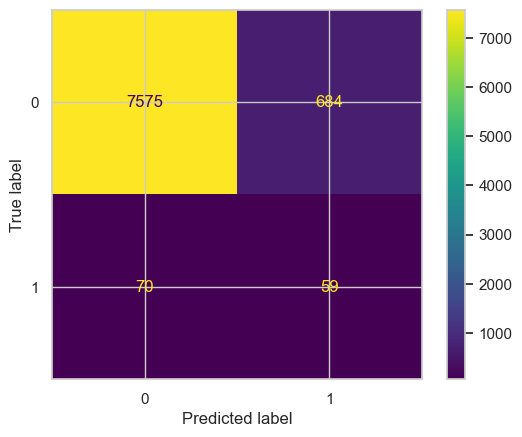

In [21]:
best_threshold = threshold_finder(lr_best, X_val, y_val)
print(f"\nBeste threshold voor F1: {best_threshold:.3f}")

y_val_proba = lr_best.predict_proba(X_val)[:, 1]
y_val_pred  = (y_val_proba >= best_threshold).astype(int)

print(f"F1-score op validatieset (met beste threshold): "
      f"{f1_score(y_val, y_val_pred):.4f}")

ConfusionMatrixDisplay.from_predictions(y_val, y_val_pred)
print(classification_report(y_val, y_val_pred))

## Support Vector Machine (SVM)

### Theorie

Een **Support Vector Machine (SVM)** is een classificatiealgoritme dat een grens zoekt tussen twee klassen. In dit onderzoek zijn dat patiënten **met** en **zonder** stroke. Het doel is een beslissingsgrens te vinden die beide groepen zo goed mogelijk van elkaar scheidt.

Bij een lineaire SVM is deze grens een recht vlak. De observaties die het dichtst bij die grens liggen, heten **support vectors**. Zij zijn het belangrijkst voor de positie van de beslissingsgrens. Een SVM probeert de marge, de ruimte tussen de grens en de dichtstbijzijnde observaties van beide klassen, zo groot mogelijk te maken.


### Soft margin en parameter `C`


In echte data zijn de groepen meestal niet perfect van elkaar te scheiden. Daarom staat een SVM fouten toe: sommige observaties mogen aan de verkeerde kant van de grens liggen. Dit heet een **soft margin**.

De parameter `C` bepaalt de afweging tussen een brede, eenvoudige grens en het correct classificeren van trainingsobservaties:

- Een **lage `C`** staat meer fouten toe en geeft een eenvoudiger model. Dit kan leiden tot underfitting.
- Een **hoge `C`** straft fouten sterker af. Het model past zich dan nauwkeuriger aan de trainingsdata aan, met een groter risico op overfitting.


### Lineaire en niet-lineaire SVM

`LinearSVC` gebruikt een lineaire beslissingsgrens. Dit model is relatief snel en geschikt voor grotere datasets, zoals deze dataset met 33.550 patiënten.

Wanneer een lineaire grens onvoldoende is, kan `SVC` met een **RBF-kernel** worden gebruikt. De RBF-kernel kan niet-lineaire patronen herkennen. Hierbij bepaalt `gamma` hoe lokaal de invloed van een observatie is:

- Een **lage `gamma`** geeft een gladdere, minder complexe beslissingsgrens.
- Een **hoge `gamma`** geeft een complexere grens die sterker op individuele observaties reageert en daardoor kan overfitten.

De parameters `C` en `gamma` worden met cross-validatie afgestemd.

### Waarom schalen nodig is



SVM's zijn gevoelig voor de schaal van variabelen. In deze dataset hebben kenmerken zoals `avg_glucose_level` en `age` een veel groter bereik dan dummyvariabelen met alleen de waarden 0 en 1. Zonder schaling kunnen kenmerken met grote waarden te veel invloed krijgen op het model.

Daarom wordt `StandardScaler` gebruikt. Deze preprocessing wordt in een `Pipeline` geplaatst, zodat de scaler alleen op de trainingsdata wordt geleerd. Hiermee wordt datalekken voorkomen.

### Class imbalance en evaluatie

Slechts 1,54% van de patiënten in de dataset heeft een stroke. Daarom wordt `class_weight='balanced'` gebruikt, zodat fouten bij de zeldzame klasse zwaarder meetellen. Ook wordt gestratificeerde cross-validatie toegepast, zodat de verhouding tussen strokes en geen strokes in elke fold behouden blijft.

De prestaties worden primair beoordeeld met de **F1-score**. Deze maat combineert precision en recall en is geschikter dan accuracy bij een sterk ongebalanceerde targetvariabele.

### Praktische keuze



Een SVM met RBF-kernel kan bij grote datasets rekenintensief zijn. Daarom vormt `LinearSVC` een praktisch uitgangspunt. Een RBF-SVM wordt alleen als aanvullende variant getest met een beperkte hyperparameterzoektocht. Voor beide varianten kan de beslissingsdrempel worden geoptimaliseerd op basis van de F1-score, omdat de standaarddrempel niet noodzakelijk de beste resultaten geeft voor de zeldzame stroke-klasse.


In [22]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, RepeatedStratifiedKFold, RandomizedSearchCV, GridSearchCV, TunedThresholdClassifierCV,cross_val_predict

from sklearn.metrics import ConfusionMatrixDisplay, classification_report, precision_recall_curve

from sklearn.model_selection import cross_val_score
from sklearn.metrics import f1_score
from sklearn.linear_model import LogisticRegression


In [23]:
pd.set_option("display.max_columns", 30)
data = pd.read_csv('train.csv')

In [24]:
dropcols = ['id', 'gender_Male', 'ever_married_No', 'work_type_Govt_job', 'Residence_type_Rural']

In [25]:
df = data.drop(dropcols, axis=1)

In [26]:
def bool_to_num(dataframe):

    """ 
    Maak boolean kolommen nummeriek.
    Geef data set terug met omgezette kolommen.
    """

    for i in dataframe.select_dtypes(include='bool').columns:
        dataframe[i] = dataframe[i].astype(int)

    return dataframe

    


def standardiseer(X_train, X_test):

    """
    Standaardiseer X_train en X_test individueel
    Geef twee datasets terug met gestandaardiseerde waarden.
    """

    scaler = StandardScaler()
    train = scaler.fit_transform(X_train) #Gemiddelde en standaarddeviatie wordt berekend op traindata
    test = scaler.transform(X_test)       #Gemiddelde en standaarddeviatie wordt overgenomen van traindata --> geen data-lekkage

    return train, test


In [27]:
df_stroke = bool_to_num(df) 

X = df_stroke.drop('stroke', axis=1) 
y = df_stroke['stroke']


X_train, X_val, y_train, y_val = train_test_split(X, y, stratify=y, random_state=42)
X_train, X_val = standardiseer(X_train, X_val)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42) #gebruik deze cross validation bij hyperparameter tunen

In [28]:
test_df = pd.read_csv('test.csv')
test_ids = test_df['id']          # id's bewaren voordat je kolommen dropt

X_test_final = bool_to_num(test_df).drop(dropcols, axis=1)

#Fit je model hierop voor het submitten
X_train_final = df_stroke.drop('stroke', axis=1) 
y_train_final = df_stroke['stroke']

X_train_final, X_test_final = standardiseer(X_train_final, X_test_final)

### Support Vector Machine (SVM)

#### SVM base model

In [29]:
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
svm_basis = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf"))
])

svm_basis.fit(X_train, y_train)
y_pred = svm_basis.predict(X_val)

#ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
#print(classification_report(y_val, y_pred, digits=3, zero_division=0))

svc_basis = svm_basis.named_steps["svm"]
#print(f"Aantal support vectors: {svc_basis.support_vectors_.shape[0]}")
#print(f"Per klasse (geen stroke / stroke): {svc_basis.n_support_}")

#### SVM class weight balanced 

In [30]:
svm_bal = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(kernel="rbf", class_weight="balanced"))
])

svm_bal.fit(X_train, y_train)
y_pred = svm_bal.predict(X_val)

#ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
#print(classification_report(y_val, y_pred, digits=3, zero_division=0))

#### SVM hyperparameter

In [31]:
indices = np.arange(len(X_train))

_, sub_idx = train_test_split(
    indices,
    test_size=6000,
    stratify=y_train,
    random_state=42
)

if hasattr(X_train, "iloc"):
    X_sub = X_train.iloc[sub_idx]
else:
    X_sub = X_train[sub_idx]

y_sub = np.asarray(y_train)[sub_idx]

print(f"Subsample: {X_sub.shape[0]} rijen, "f"waarvan {y_sub.sum()} met stroke "f"({y_sub.mean():.2%})")

Subsample: 6000 rijen, waarvan 93 met stroke (1.55%)


#### Hyperparameters tunen

In [32]:
param_grid = {
    "svm__C": [0.1, 1, 10, 100],
    "svm__gamma": [0.001, 0.01, 0.1, "scale"],
}

cv_svm = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

svm_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        class_weight="balanced",
        cache_size=1000
    ))
])

grid = GridSearchCV(
    estimator=svm_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv_svm,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

grid.fit(X_sub, y_sub)

print(f"Beste parameters: {grid.best_params_}")
print(f"Beste F1-score in cross-validatie: {grid.best_score_:.4f}")

Fitting 3 folds for each of 16 candidates, totalling 48 fits
Beste parameters: {'svm__C': 0.1, 'svm__gamma': 'scale'}
Beste F1-score in cross-validatie: 0.0880


#### Overzicht van alle hyperparameter resultaten 

In [33]:
resultaten = pd.DataFrame(grid.cv_results_)[
    [
        "param_svm__C",
        "param_svm__gamma",
        "mean_test_score",
        "std_test_score",
        "rank_test_score",
    ]
]

resultaten = resultaten.sort_values(
    "mean_test_score",
    ascending=False
)

print(resultaten.to_string(index=False))

 param_svm__C param_svm__gamma  mean_test_score  std_test_score  rank_test_score
          0.1            scale         0.087951        0.004561                1
        100.0            0.001         0.084796        0.003383                2
          0.1             0.01         0.084392        0.005182                3
          1.0            0.001         0.083942        0.006253                4
         10.0            0.001         0.083752        0.005822                5
          0.1            0.001         0.082791        0.004435                6
          1.0             0.01         0.081985        0.009241                7
          0.1              0.1         0.077184        0.005341                8
         10.0             0.01         0.074331        0.002810                9
        100.0             0.01         0.066730        0.008783               10
         10.0            scale         0.057202        0.005847               11
          1.0            sca

#### Hertrainen op de volledige trainingsset en eerste validatie


In [34]:
svm_best = grid.best_estimator_

svm_best.fit(X_train, y_train)

y_pred = svm_best.predict(X_val)

#ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
#print(classification_report(y_val, y_pred, digits=3, zero_division=0))

svc_best = svm_best.named_steps["svm"]
aantal_sv = svc_best.support_vectors_.shape[0]

print(
    f"Support vectors: {aantal_sv} "
    f"({aantal_sv / len(X_train):.1%} van de trainingsset)"
)

Support vectors: 12269 (48.8% van de trainingsset)


#### Cross validation met de beste SVM model

In [35]:
cv_scores = cross_val_score(
    svm_best,
    X_train,
    y_train,
    cv=cv_svm,
    scoring="f1",
    n_jobs=-1
)

print(f"F1-score per fold: {np.round(cv_scores, 4)}")
print(
    f"Gemiddelde F1-score: {cv_scores.mean():.4f} "
    f"(+/- {cv_scores.std():.4f})"
)

Exception ignored in: <function ResourceTracker.__del__ at 0x106241bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


F1-score per fold: [0.0846 0.093  0.0917]
Gemiddelde F1-score: 0.0898 (+/- 0.0037)


Exception ignored in: <function ResourceTracker.__del__ at 0x111739bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1047fdbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


#### SVM eindmodel 

In [36]:
def threshold_finder_svm(model, X_data, y_data):
    """
    Zoekt de threshold op de decision function die de F1-score maximaliseert.
    """
    scores = model.decision_function(X_data)

    precision, recall, thresholds = precision_recall_curve(y_data, scores)

    f1_scores = (
        2 * precision[:-1] * recall[:-1]
        / (precision[:-1] + recall[:-1] + 1e-12)
    )

    return thresholds[np.argmax(f1_scores)]

In [37]:
train_scores_oof = cross_val_predict(
    svm_best,
    X_train,
    y_train,
    cv=cv_svm,
    method="decision_function",
    n_jobs=-1
)

precision, recall, thresholds = precision_recall_curve(
    y_train,
    train_scores_oof
)

f1_scores = (
    2 * precision[:-1] * recall[:-1]
    / (precision[:-1] + recall[:-1] + 1e-12)
)

best_threshold = thresholds[np.argmax(f1_scores)]

print(f"Beste threshold op out-of-fold trainingsscores: {best_threshold:.4f}")
print(f"Beste out-of-fold F1-score: {np.max(f1_scores):.4f}")

Exception ignored in: <function ResourceTracker.__del__ at 0x105779bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


Beste threshold op out-of-fold trainingsscores: 0.8471
Beste out-of-fold F1-score: 0.1158


Exception ignored in: <function ResourceTracker.__del__ at 0x105a01bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1057d1bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes


              precision    recall  f1-score   support

           0      0.990     0.912     0.950      8259
           1      0.068     0.411     0.117       129

    accuracy                          0.905      8388
   macro avg      0.529     0.662     0.533      8388
weighted avg      0.976     0.905     0.937      8388

F1-score op de onafhankelijke validatieset (met vaste threshold): 0.1170


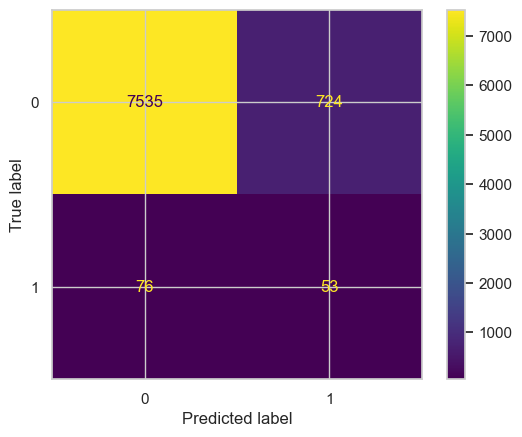

In [38]:
# svm_best is al gefit op de volledige trainingsset.
val_scores = svm_best.decision_function(X_val)

y_pred_threshold = (
    val_scores >= best_threshold
).astype(int)

ConfusionMatrixDisplay.from_predictions(y_val, y_pred_threshold)

print(
    classification_report(
        y_val,
        y_pred_threshold,
        digits=3,
        zero_division=0
    )
)

print(
    "F1-score op de onafhankelijke validatieset "
    f"(met vaste threshold): {f1_score(y_val, y_pred_threshold):.4f}"
)

## Decision Trees

### Theorie



#### Hoe werkt het model?

Een **Decision Tree** is een supervised learning-algoritme dat voorspellingen doet door een reeks ja/nee-vragen te stellen over de features. Het model bouwt tijdens het trainen een boomstructuur op, waarbij:

1. De **root node** (bovenaan) de volledige dataset bevat.
2. Elke **interne node** een vraag stelt over één feature (bijv. *"is leeftijd > 65?"*).
3. Elke **branch** een mogelijke uitkomst van die vraag voorstelt.
4. Elke **leaf node** (onderaan) een uiteindelijke voorspelling bevat (in ons geval: *stroke* of *geen stroke*).

Bij het voorspellen van een nieuw datapunt wandelt het model van de root naar een leaf door bij elke node de vraag te beantwoorden op basis van de feature-waarden. De klasse die in die leaf domineert, wordt de voorspelling.

In tegenstelling tot KNN hoeven features **niet geschaald** te worden, omdat splitsingen gemaakt worden op basis van drempelwaarden per feature afzonderlijk. Het maakt niet uit of `avg_glucose_level` in de honderden ligt en `hypertension` in 0/1 — elke feature wordt onafhankelijk beoordeeld.

#### Op basis waarvan worden splitsingen gemaakt?

Bij elke node kiest het algoritme de **feature en drempelwaarde** die de data het best scheidt in homogene groepen (groepen waarin één klasse overheerst). Om te bepalen wat "best scheidt" betekent, worden **splitsingscriteria** gebruikt. De drie meest voorkomende zijn:

- **Gini impurity** (standaard in scikit-learn): meet de kans dat een willekeurig gekozen punt verkeerd geclassificeerd wordt als je willekeurig een klasse toewijst volgens de klasseverdeling in die node. Lagere Gini = zuiverder splitsing.
- **Entropy** (information gain): meet de "wanorde" in een node. Een splitsing die de entropy sterk verlaagt levert veel informatie op. Entropy geeft vaak vergelijkbare bomen als Gini, maar is iets duurder om te berekenen.
- **Log loss**: lijkt op entropy en wordt gebruikt wanneer je direct de probabilistische output van de boom wilt optimaliseren.

Het algoritme probeert bij elke node alle mogelijke splitsingen (per feature, per drempelwaarde) en kiest degene die het gekozen criterium het meest verlaagt. Dit proces herhaalt zich recursief totdat een stopcriterium wordt bereikt (bijv. maximale diepte, minimum aantal samples per leaf, of een leaf die volledig zuiver is).

#### Hyperparameter tuning

Decision Trees hebben relatief veel hyperparameters die de complexiteit (en dus overfitting) sterk beïnvloeden. Met behulp van **GridSearchCV** (RepeatedStratifiedKFold, scoring op F1) zoeken we de beste combinatie van onderstaande hyperparameters:

| Hyperparameter | Geteste waarden | Wat het doet |
|---|---|---|
| `criterion` | `gini`, `entropy` | Splitsingscriterium (zie hierboven) |
| `max_depth` | 3, 5, 7, 10, None | Maximale diepte van de boom (hoofdrem tegen overfitting) |
| `min_samples_split` | 2, 10, 20 | Minimum aantal samples nodig om een node te splitsen |
| `min_samples_leaf` | 1, 5, 10 | Minimum aantal samples in een leaf |
| `ccp_alpha` | 0.0, 0.001, 0.01, 0.05 | Cost-complexity pruning parameter (zie onder) |

Net als bij KNN gebruiken we **F1-score** als scoring-metric, omdat de dataset imbalanced is en F1 een eerlijke balans tussen precision en recall afdwingt.

#### Wat is pruning en hoe werkt het?

**Pruning** betekent letterlijk "snoeien": het verwijderen of beperken van takken en bladeren uit de boom om overfitting tegen te gaan. Een ongeremde Decision Tree groeit namelijk door tot élke leaf perfect zuiver is, wat betekent dat hij de trainingsdata uit zijn hoofd leert en slecht generaliseert naar nieuwe data.

Er zijn twee hoofdvormen van pruning:

**1. Pre-pruning (early stopping)**
De boom wordt al tijdens het bouwen beperkt met behulp van hyperparameters zoals `max_depth`, `min_samples_split` en `min_samples_leaf`. Zodra een stopcriterium wordt bereikt, stopt de boom met verder splitsen. Dit is efficiënt omdat de boom nooit onnodig groot wordt.

**2. Post-pruning (cost-complexity pruning)**
De boom wordt eerst volledig uitgebouwd, en pas daarna worden takken teruggesnoeid die weinig bijdragen aan de voorspellende kracht. In scikit-learn gebeurt dit via de parameter `ccp_alpha`: hoe hoger deze waarde, hoe meer takken verwijderd worden. Nul betekent geen pruning, hoge waarden geven een zeer kleine boom.

#### Relatie tussen pruning en under-/overfitting

Pruning is precies het instrument om de balans te vinden tussen onder- en overfitting:

- **Geen of weinig pruning** → de boom wordt heel diep en complex → **overfitting**: hoge accuracy op training, lage score op validatie, omdat de boom ruis en uitschieters in de trainingsdata heeft gememoriseerd.
- **Te veel pruning** → de boom wordt te klein en simpel → **underfitting**: het model mist belangrijke patronen en presteert zowel op training als validatie slecht.
- **Juiste mate van pruning** → de boom heeft genoeg capaciteit om echte patronen te leren, maar negeert ruis → goede generalisatie naar nieuwe data.

De juiste hoeveelheid pruning vinden we via cross-validation tijdens de hyperparameter tuning: de combinatie van `max_depth`, `min_samples_leaf` en `ccp_alpha` die de hoogste F1-score oplevert op de validatie-folds, is de optimale balans.

#### Omgaan met class imbalance

Omdat de dataset veel meer "geen stroke" dan "stroke" patiënten bevat, zou een standaard Decision Tree snel geneigd zijn om bijna altijd "geen stroke" te voorspellen. We passen twee technieken toe:

**1. `class_weight='balanced'`**
Deze ingebouwde optie laat de boom de minderheidsklasse zwaarder meewegen tijdens het berekenen van de splitsingscriteria. Een foute voorspelling op een stroke-patiënt "kost" meer dan een foute voorspelling op een gezonde patiënt, waardoor de boom gemotiveerd wordt om ook splitsingen te maken die stroke-patiënten correct identificeren.

**2. Threshold-optimalisatie**
Standaard gebruikt scikit-learn een drempelwaarde van 0.5 om kansen om te zetten in voorspellingen. Omdat de klasseverdeling scheef is, is 0.5 bijna nooit optimaal. Met `threshold_finder()` zoeken we op de validatieset de drempelwaarde die de F1-score maximaliseert, en passen we die toe op de uiteindelijke voorspellingen.


Gemiddelde F1 (cross-validation): 0.0542 (± 0.0223)

F1-score per waarde van max_depth:
  max_depth=   3  :  F1-score: 0.0740
  max_depth=   5  :  F1-score: 0.0825
  max_depth=   7  :  F1-score: 0.0758
  max_depth=  10  :  F1-score: 0.0814
  max_depth=None  :  F1-score: 0.0351
Fitting 15 folds for each of 360 candidates, totalling 5400 fits

Beste parameters: {'ccp_alpha': 0.001, 'criterion': 'entropy', 'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 10}
Beste F1 (cross-validation): 0.0962

Beste threshold voor F1: 0.842
F1-score op validatieset (met beste threshold): 0.1010
              precision    recall  f1-score   support

           0       0.75      1.00      0.86      6219
           1       0.80      0.05      0.09      2169

    accuracy                           0.75      8388
   macro avg       0.77      0.52      0.47      8388
weighted avg       0.76      0.75      0.66      8388


Submission opgeslagen als 'submission_decision_tree.csv' (992 positieve voo

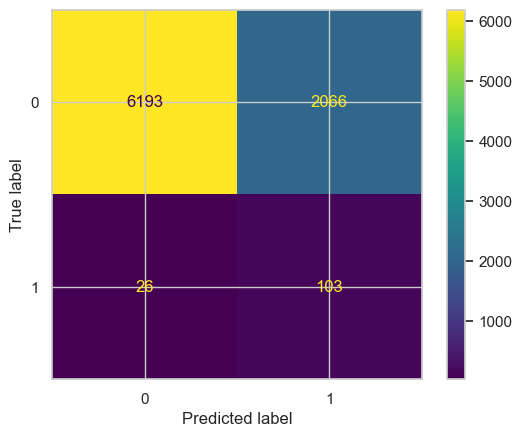

In [39]:
dt = DecisionTreeClassifier(class_weight='balanced', random_state=42)
dt.fit(X_train, y_train)

# Cross-validation score (F1, want de dataset is imbalanced)
cv_scores = cross_val_score(dt, X_train, y_train, cv=cv, scoring='f1')
print(f"Gemiddelde F1 (cross-validation): {cv_scores.mean():.4f} "
      f"(± {cv_scores.std():.4f})")


print("\nF1-score per waarde van max_depth:")
for depth in [3, 5, 7, 10, None]:
    model = DecisionTreeClassifier(
        max_depth=depth,
        class_weight='balanced',
        random_state=42
    )
    model.fit(X_train, y_train)
    y_pred_d = model.predict(X_val)
    f1 = f1_score(y_val, y_pred_d)
    label = depth if depth is not None else "None"
    print(f"  max_depth={str(label):>4}  :  F1-score: {f1:.4f}")

# We tunen op F1-score (Kaggle-metric) met dezelfde cross-validation
# als bij KNN (RepeatedStratifiedKFold 5x3). class_weight='balanced'
# staat vast omdat het onze imbalance-techniek is.
# ccp_alpha wordt meegetuned om post-pruning direct mee te nemen.

param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 10, 20],
    'min_samples_leaf': [1, 5, 10],
    'ccp_alpha': [0.0, 0.001, 0.01, 0.05],
}

grid = GridSearchCV(
    estimator=DecisionTreeClassifier(class_weight='balanced', random_state=42),
    param_grid=param_grid,
    scoring='f1',
    cv=cv,
    n_jobs=-1,
    verbose=1,
)
grid.fit(X_train, y_train)

print(f"\nBeste parameters: {grid.best_params_}")
print(f"Beste F1 (cross-validation): {grid.best_score_:.4f}")

dt_best = grid.best_estimator_

best_threshold = threshold_finder(dt_best, X_val, y_val)
print(f"\nBeste threshold voor F1: {best_threshold:.3f}")

# Voorspellingen op validatieset met geoptimaliseerde threshold
y_val_proba = dt_best.predict_proba(X_val)[:, 1]
y_val_pred  = (y_val_proba >= best_threshold).astype(int)

print(f"F1-score op validatieset (met beste threshold): "
      f"{f1_score(y_val, y_val_pred):.4f}")

dt_final = DecisionTreeClassifier(
    **grid.best_params_,
    class_weight='balanced',
    random_state=42,
)
dt_final.fit(X_train_final, y_train_final)

# Voorspellingen op de test-set (Kaggle)
test_proba = dt_final.predict_proba(X_test_final)[:, 1]
test_pred  = (test_proba >= best_threshold).astype(int)

ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
print(classification_report(y_pred, y_val))

# Submission-bestand aanmaken
submission = pd.DataFrame({
    'id': test_ids,
    'stroke': test_pred
})
submission.to_csv('submission_decision_tree.csv', index=False)
print(f"\nSubmission opgeslagen als 'submission_decision_tree.csv' "
      f"({submission['stroke'].sum()} positieve voorspellingen "
      f"van {len(submission)} patiënten)")

## 3.5 Ensembles

## Random Forest

Random Forest is de eerste van de drie bekende ensembles die zullen worden gebruikt. Dit model maakt gebruik van verschillende beslisbomen die samen 'stemmen' om de juiste voorspelling te maken (Breiman, 2001). Er wordt gebruik gemaakt van een methode genaamd 'Bagging' (Bootstrap Aggregation). Hierbij wordt parallel per beslisboom een gedeelte uit de dataset genomen om hierop te trainen, waardoor een hoop verschillende combinaties van rijen uit de traindata per boom mogelijk zijn. Door de parallele trainingsvorm is dit model sneller dan `GradientBoostedClassifier`, wel zijn de bomen vaak dieper, waardoor het minder snel is dan XGBoost. Elke beslisboom is dus anders (Ho, 1995), waardoor zwakke of overfitte bomen minder sterk meewegen (Kleinberg, 1996; Breiman, 2001).

### Omgang met class imbalance

Om om te gaan met de scheve verdeling van de klassen die moeten worden voorspeld, zijn bij Random Forest drie methoden toegepast.

**1. SMOTE**

SMOTE (Synthetic Minority Oversampling Technique) maakt extra voorbeelden van de minderheidsklasse (Chawla et al., 2002). Hierbij worden telkens twee dichtbij elkaar liggende punten van die klasse genomen en wordt er een nieuw voorbeeld tussen beide in gemaakt. Het minderheidsgeval komt daardoor vaker voor, en het model heeft meer voorbeelden om van te leren.

**2. Class weight**

Bij het hyperparameter tunen wordt gekozen tussen `class_weight='balanced'` en `class_weight='balanced_subsample'` (Pedregosa et al., 2011). Beide methoden passen de loss-functie aan, zodat fouten op de minderheidsklasse zwaarder wegen. Het verschil zit in de manier waarop de gewichten worden berekend: `'balanced_subsample'` berekent ze per bootstrap-steekproef van elke boom.

**3. Threshold-optimalisatie**

Met `TunedThresholdClassifierCV` wordt de classificatiedrempel (threshold) bepaald die de hoogste F1-score oplevert binnen de parameter search (Pedregosa et al., 2011). Bij zo'n grote onbalans kan de juiste threshold een groot verschil maken, omdat de standaarddrempel van 0,5 dan vaak niet optimaal is.





Standaard model -- geen toevoegingen

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      8259
           1       0.50      0.01      0.02       129

    accuracy                           0.98      8388
   macro avg       0.74      0.50      0.50      8388
weighted avg       0.98      0.98      0.98      8388



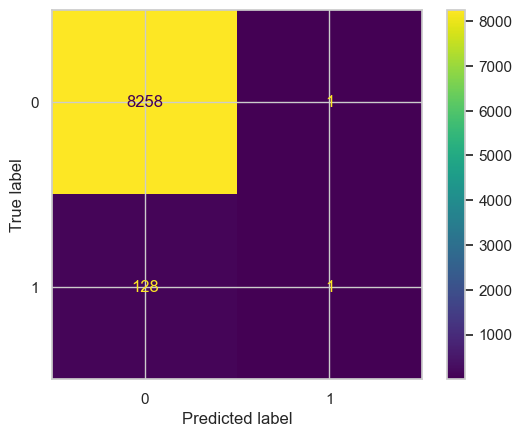

In [40]:
rf = RandomForestClassifier(random_state=42)


rf.fit(X_train, y_train)
y_pred = rf.predict(X_val)

ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
print(classification_report(y_val, y_pred))

Hyperparameters tunen met cross validation

In [41]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

pipe = Pipeline([
    ("smote", SMOTE(random_state=42)),
    ("model", RandomForestClassifier(random_state=42)),
])

tuned = TunedThresholdClassifierCV(
    estimator=pipe,
    scoring="f1",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    thresholds=100,
    refit=True,
)

param_dist = {
    "estimator__model__n_estimators": randint(100, 500),
    "estimator__model__max_depth": randint(3, 25),
    "estimator__model__min_samples_leaf": randint(1, 30),
    "estimator__model__min_samples_split": randint(2, 30),
    "estimator__model__max_features": ["sqrt", "log2", 0.3, 0.5],
    "estimator__model__class_weight": ["balanced", "balanced_subsample"],
}

search = RandomizedSearchCV(
    tuned,
    param_dist,
    n_iter=30,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
)

#search.fit(X_train, y_train)

#best_model = search.best_estimator_
#best_params = best_model.estimator_.get_params()

#set_config(print_changed_only=False)
#pprint.pprint(best_model.get_params(deep=True), width=120)

Hyperparameters na het tunen definieren (zodat de search niet vaker dan nodig hoeft te runnen)

In [42]:
rf = TunedThresholdClassifierCV(
    estimator=Pipeline(steps=[
        ("smote", SMOTE(k_neighbors=5, random_state=42, sampling_strategy="auto")),
        ("model", RandomForestClassifier(
            bootstrap=True,
            ccp_alpha=0.0,
            class_weight="balanced_subsample",
            criterion="gini",
            max_depth=4,
            max_features="sqrt",
            min_impurity_decrease=0.0,
            min_samples_leaf=16,
            min_samples_split=24,
            min_weight_fraction_leaf=0.0,
            n_estimators=161,
            oob_score=False,
            random_state=42,
            warm_start=False,
        )),
    ]),
    cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
    scoring="f1",
    thresholds=100,
    refit=True,
)

In [43]:
rf.fit(X_train, y_train)

y_pred = rf.predict(X_val)

print(classification_report(y_pred, y_val))
ConfusionMatrixDisplay.from_predictions(y_val, y_pred)

TypeError: All intermediate steps should be transformers and implement fit and transform or be the string 'passthrough' 'SMOTE(random_state=42)' (type <class 'imblearn.over_sampling._smote.base.SMOTE'>) doesn't

Kaggle submit

In [ ]:
rf.fit(X_train_final, y_train_final)
y_pred = rf.predict(X_test_final)

submission = pd.DataFrame({
    'id': test_ids,
    'stroke': y_pred,
})
#submission.to_csv('submission_rf_final.csv', index=False)

## Gradient Boosted Trees

Dit model pakt het iets anders aan. Er wordt gebruik gemaakt van gradient boosting (Friedman, 2001). Hierbij worden meerdere zwakke bomen gebruikt om deze sequentieel te verbeteren door in elke iteratie de pseudo-residuen te voorspellen. Het model probeert dus in elke iteratie een steeds kleinere loss te minimaliseren. Het begint met een constante voorspelling die de loss minimaliseert, bijvoorbeeld het gemiddelde van de doelvariabele bij regressie met kwadratische fout. Daarna wordt in elke iteratie de pseudo-residu berekend: de negatieve gradient van de loss-functie ten opzichte van de huidige voorspelling. Een nieuwe, kleine boom wordt op deze pseudo-residuen getraind, en de voorspelling van die boom wordt vermenigvuldigd met een learning rate en bij de bestaande voorspelling opgeteld. Doordat elke boom maar een beperkte bijdrage levert, wordt overfitting tegengegaan en daalt de loss stap voor stap (Friedman, 2001). Door deze sequentiële trainingsvorm is dit het langzaamste ensemble van de drie, omdat elke iteratie achter elkaar moet gebeuren en niet tegelijk kan.


### Omgang met class inbalance 

Dit model maakt net als Random Forest gebruik van SMOTE en een TunedThresholdClassifier. De uitleg hiervan staat bij dat model beschreven.

Standaard model -- geen toevoegingen

              precision    recall  f1-score   support

           0       1.00      0.98      0.99      8380
           1       0.01      0.12      0.01         8

    accuracy                           0.98      8388
   macro avg       0.50      0.55      0.50      8388
weighted avg       1.00      0.98      0.99      8388



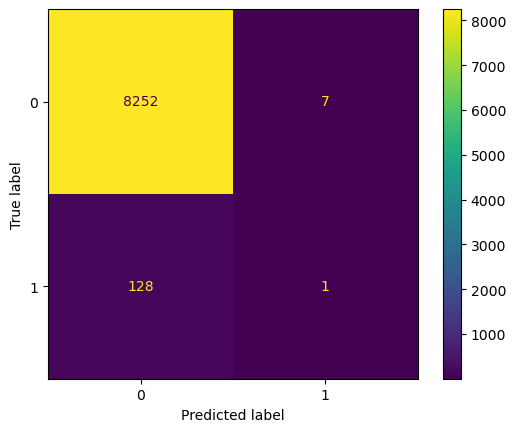

In [ ]:
gb = GradientBoostingClassifier(random_state=42)

gb.fit(X_train, y_train)

y_pred = gb.predict(X_val)



ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
print(classification_report(y_pred, y_val))

Hyperparameters tunen met cross validation

In [ ]:
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42) 

pipe = Pipeline([                                                  
    ("smote", SMOTE(random_state=42)),                             
    ("model", GradientBoostingClassifier(random_state=42)),           
])

tuned = TunedThresholdClassifierCV(                              
    estimator=pipe,
    scoring="f1",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    thresholds=100,
    refit=True,
)

param_dist = {
    "estimator__model__learning_rate": loguniform(0.01, 0.2),
    "estimator__model__n_estimators": randint(200, 1500),
    "estimator__model__max_depth": randint(2, 7),
    "estimator__model__min_samples_leaf": randint(5, 60),
    "estimator__model__subsample": uniform(0.6, 0.4),
    "estimator__model__max_features": uniform(0.4, 0.6),
    "estimator__model__min_impurity_decrease": uniform(0, 0.01),
}

search = RandomizedSearchCV(
    estimator= tuned,              
    param_distributions=param_dist,
    n_iter=30,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2
)

#search.fit(X_train, y_train)             
#best_model = search.best_estimator_
#best_params = best_model.estimator_.get_params()

#set_config(print_changed_only=False)
#pprint.pprint(best_model.get_params(deep=True), width=120)

Fitting 15 folds for each of 30 candidates, totalling 450 fits
{'cv': StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
 'estimator': Pipeline(memory=None,
         steps=[('smote',
                 SMOTE(k_neighbors=5, n_jobs=None, random_state=42,
                       sampling_strategy='auto')),
                ('model',
                 GradientBoostingClassifier(ccp_alpha=0.0,
                                            criterion='friedman_mse', init=None,
                                            learning_rate=0.04435424810484039,
                                            loss='log_loss', max_depth=2,
                                            max_features=0.48885215797203996,
                                            max_leaf_nodes=None,
                                            min_impurity_decrease=0.009977404850489419,
                                            min_samples_leaf=53,
                                            min_samples_split=2,
         

Hyperparameters na het tunen definieren (zodat de search niet vaker dan nodig hoeft te runnen)

In [ ]:
gb = TunedThresholdClassifierCV(
    estimator=Pipeline(steps=[
        ("smote", SMOTE(k_neighbors=5, random_state=42, sampling_strategy="auto")),
        ("model", GradientBoostingClassifier(
            criterion="friedman_mse",
            learning_rate=0.04435424810484039,
            loss="log_loss",
            max_depth=2,
            max_features=0.48885215797203996,
            min_impurity_decrease=0.009977404850489419,
            min_samples_leaf=53,
            n_estimators=201,
            random_state=42,
            subsample=0.8010716092915446,
        )),
    ]),
    cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
    scoring="f1",
    thresholds=100,
    refit=True,
)

              precision    recall  f1-score   support

           0       0.97      0.99      0.98      8125
           1       0.15      0.07      0.10       263

    accuracy                           0.96      8388
   macro avg       0.56      0.53      0.54      8388
weighted avg       0.94      0.96      0.95      8388



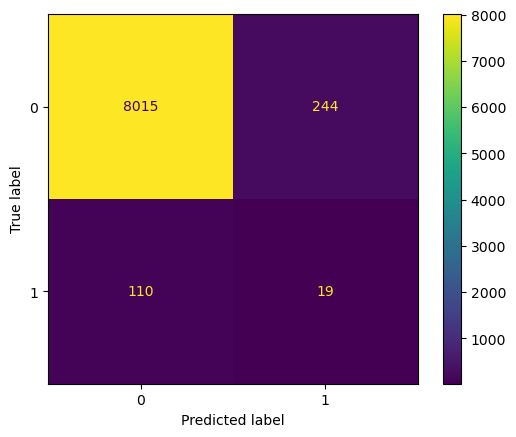

In [ ]:
gb.fit(X_train, y_train)
y_pred = gb.predict(X_val)


ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
print(classification_report(y_pred, y_val))

kaggle submit

In [ ]:
gb.fit(X_train_final, y_train_final)


y_pred = gb.predict(X_test_final)

submission = pd.DataFrame({
    "id": test_ids,
    "stroke": y_pred,
})
#submission.to_csv("submission_GBtree_threshold.csv", index=False)

## XGBoost

XGBoost staat voor extreme gradient boosting. Het is een open source library en ook gebaseerd op een gradient boosted algoritme, alleen het is een stuk geavanceerder dan de standaard `GradientBoostedClassifier`. Het is sneller, omdat het parallelisatie gebruikt om bomen sneller te berekenen. Het heeft ingebouwde regularisatie tegen overfitting, en het kan automatisch omgaan met missende data (GeeksforGeeks, 2026). Voor ons project is het handig dat de regularisatie is ingebouwd.

### Omgang met class imbalance

Dit model maakt net als de andere twee gebruik van `TunedThresholdClassifierCV`. Echter wordt hier ook een andere techniek toegepast, namelijk `scale_pos_weight`. Dit is een parameter van XGBoost die de weging van de minderheidsklasse bepaalt. De waarde wordt berekend als het aantal negatieve rijen gedeeld door het aantal positieve rijen (Chen & Guestrin, 2016). Dit geeft een vaste weging die wordt meegenomen in de loss-functie, waardoor het model vaker fouten op de minderheidsklasse moet corrigeren en er dus meer aandacht aan die klasse wordt besteed.

Standaard model -- geen toevoegingen

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      8259
           1       0.11      0.01      0.01       129

    accuracy                           0.98      8388
   macro avg       0.55      0.50      0.50      8388
weighted avg       0.97      0.98      0.98      8388



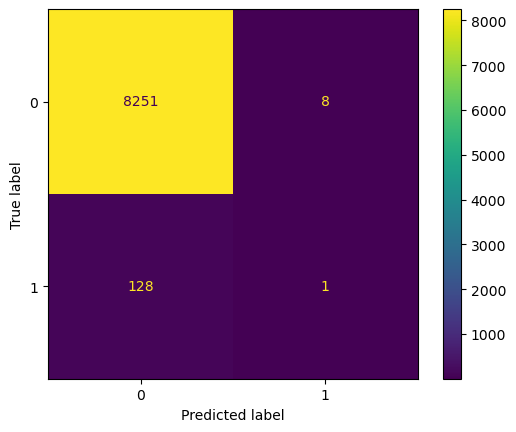

In [ ]:
xgboost = xgb.XGBClassifier(random_state=42)

xgboost.fit(X_train, y_train)
y_pred = xgboost.predict(X_val)

ConfusionMatrixDisplay.from_predictions(y_val, y_pred)
print(classification_report(y_val, y_pred))

Hyperparameters tunen met cross validation

In [ ]:
n_neg = (y_train == 0).sum()
n_pos = (y_train == 1).sum()

if n_pos == 0:
    raise ValueError("y_train bevat geen positieve klasse (1).")

scale_pos_weight = n_neg / n_pos
print(f"scale_pos_weight: {scale_pos_weight:.3f}")


cv = RepeatedStratifiedKFold(
    n_splits=3,
    n_repeats=3,
    random_state=42,
)


pipe = Pipeline([
    ("model", XGBClassifier(
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=42,
        n_jobs=1,  
        scale_pos_weight=scale_pos_weight,
    )),
])


tuned = TunedThresholdClassifierCV(
    estimator=pipe,
    scoring="f1",
    cv=StratifiedKFold(n_splits=3, shuffle=True, random_state=42),
    thresholds=200,
    refit=True,
)

param_dist = {
    "estimator__model__n_estimators": randint(200, 2001),
    "estimator__model__max_depth": randint(2, 11),
    "estimator__model__learning_rate": loguniform(0.005, 0.2),
    "estimator__model__subsample": uniform(0.6, 0.4),
    "estimator__model__colsample_bytree": uniform(0.5, 0.5),
    "estimator__model__min_child_weight": randint(1, 16),
    "estimator__model__gamma": loguniform(1e-4, 2.0),
    "estimator__model__reg_alpha": loguniform(1e-5, 10.0),
    "estimator__model__reg_lambda": loguniform(1e-3, 100.0),
}

search = RandomizedSearchCV(
    estimator=tuned,
    param_distributions=param_dist,
    n_iter=150,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=False,
)


#search.fit(X_train, y_train)

#best_model = search.best_estimator_
#best_params = best_model.estimator_.get_params()

#set_config(print_changed_only=False)
#pprint.pprint(best_model.get_params(deep=True), width=120)

scale_pos_weight: 63.851


Hyperparameters na het tunen definieren (zodat de search niet vaker dan nodig hoeft te runnen)

In [ ]:
xgb_model = TunedThresholdClassifierCV(
    estimator=Pipeline(
        steps=[
            ("model", XGBClassifier(
                colsample_bytree=0.9974539113232177,
                eval_metric="logloss",
                feature_types=None,
                gamma=0.0005596656893042824,
                learning_rate=0.02156619311061098,
                max_depth=3,
                min_child_weight=2,
                n_estimators=261,
                n_jobs=1,
                objective="binary:logistic",
                random_state=42,
                reg_alpha=9.506368714217354,
                reg_lambda=30.70299488350551,
                scale_pos_weight=63.850515463917525,
                subsample=0.785352299286248,
            )),
        ]
    ),
    cv=StratifiedKFold(n_splits=3, random_state=42, shuffle=True),
    scoring="f1",
    thresholds=200,
    refit=True,
)



              precision    recall  f1-score   support

           0       0.99      0.95      0.97      8259
           1       0.07      0.25      0.11       129

    accuracy                           0.94      8388
   macro avg       0.53      0.60      0.54      8388
weighted avg       0.97      0.94      0.95      8388



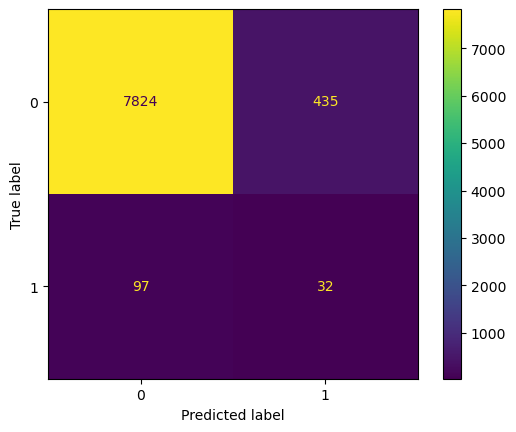

In [ ]:
xgb_model.fit(X_train, y_train)

y_pred = xgb_model.predict(X_val)

print(classification_report(y_val, y_pred))
ConfusionMatrixDisplay.from_predictions(y_val, y_pred)

Kaggle submit

In [ ]:
xgb_model.fit(X_train_final, y_train_final)


y_pred = xgb_model.predict(X_test_final)

submission = pd.DataFrame({
    "id": test_ids,
    "stroke": y_pred,
})
#submission.to_csv("submission_XGB.csv", index=False)

# 3.6 Eigen ensemble

Hyperparameter tunen

In [ ]:
stack_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

stacking = StackingClassifier(
    estimators=[
        ("lr", ImbPipeline([
            ("smote", SMOTE(k_neighbors=5, random_state=42)),
            ("model", LogisticRegression(max_iter=3000, random_state=42)),
        ])),
        ("svm", ImbPipeline([
            ("smote", SMOTE(k_neighbors=5, random_state=42)),
            ("model", LinearSVC(random_state=42, dual="auto")),
        ])),
        ("rf", rf.estimator),
    ],
    final_estimator=LogisticRegression(max_iter=3000, random_state=42),
    stack_method="auto",
    cv=stack_cv,
    n_jobs=1,
)

stack_param_dist = {
    "lr__model__C": loguniform(1e-3, 1e2),
    "lr__model__class_weight": [None, "balanced"],
    "svm__model__C": loguniform(1e-2, 1e2),
    "final_estimator__C": loguniform(1e-3, 1e2),
    "final_estimator__class_weight": [None, "balanced"],
}

stack_search = RandomizedSearchCV(
    estimator=stacking,
    param_distributions=stack_param_dist,
    n_iter=6,
    scoring="f1",
    cv=stack_cv,
    random_state=42,
    n_jobs=-1,
    verbose=2,
    refit=True,
    return_train_score=False,
)

missing_stack_params = set(stack_param_dist) - set(stacking.get_params(deep=True))
assert not missing_stack_params, f"Onbekende parameterpaden: {missing_stack_params}"
print("Alle stacking-parameterpaden zijn geldig.")

Alle stacking-parameterpaden zijn geldig.


Validatie

In [ ]:
stack_search.fit(X_train, y_train)

stack_tuned = TunedThresholdClassifierCV(
    estimator=stack_search.best_estimator_,
    scoring="f1",
    cv=stack_cv,
    thresholds=50,
    refit=True,
)
stack_tuned.fit(X_train, y_train)
stack_best_model = stack_tuned

print("Beste CV F1 voor de parameterzoektocht:", stack_search.best_score_)
print("Beste parameters:", stack_search.best_params_)
print("Gekozen threshold:", stack_best_model.best_threshold_)

y_pred = stack_best_model.predict(X_val)
print(classification_report(y_val, y_pred, zero_division=0))

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Beste CV F1 voor de parameterzoektocht: 0.09027631728316136
Beste parameters: {'final_estimator__C': 14.528246637516036, 'final_estimator__class_weight': 'balanced', 'lr__model__C': 0.0010090061869151559, 'lr__model__class_weight': 'balanced', 'svm__model__C': 0.05415244119402541}
Gekozen threshold: 0.8245923861334439
              precision    recall  f1-score   support

           0       0.99      0.94      0.96      8259
           1       0.08      0.32      0.12       129

    accuracy                           0.93      8388
   macro avg       0.53      0.63      0.54      8388
weighted avg       0.97      0.93      0.95      8388



kaggle submit

In [ ]:
stack_best_model.fit(X_train_final, y_train_final)

y_pred = stack_best_model.predict(X_test_final)

stack_submission = pd.DataFrame({
    "id": test_ids,
    "stroke": y_pred,
})
#stack_submission.to_csv("eigen_ensemble.csv", index=False)

---


### Bronvermelding

Scikit-learn developers. (z.d.). *StandardScaler*. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html  

Scikit-learn developers. (z.d.). *StratifiedKFold*. https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html  

Scikit-learn developers. (z.d.). *F1 score*. https://scikit-learn.org/stable/modules/generated/sklearn.metrics.f1_score.html

Scikit-learn developers. (z.d.). Support vector machines. https://scikit-learn.org/stable/modules/svm.html

Scikit-learn developers. (z.d.). LogisticRegression. https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html

Breiman, L. (2001). Random forests. *Machine Learning, 45*(1), 5–32. https://doi.org/10.1023/A:1010933404324

Friedman, J. H. (2001). Greedy function approximation: A gradient boosting machine. *The Annals of Statistics, 29*(5), 1189–1232.

GeeksforGeeks. (2026, March 19). *XGBoost*. https://www.geeksforgeeks.org/machine-learning/xgboost/

Ho, T. K. (1995). Random decision forests. In *Proceedings of the 3rd International Conference on Document Analysis and Recognition* (pp. 278–282). IEEE.

Kleinberg, E. M. (1996). An overtraining-resistant stochastic modeling method for pattern recognition. *The Annals of Statistics, 24*(6), 2319–2349. https://doi.org/10.1214/aos/1032181157

Chawla, N. V., Bowyer, K. W., Hall, L. O., & Kegelmeyer, W. P. (2002). SMOTE: Synthetic minority over-sampling technique. *Journal of Artificial Intelligence Research, 16*, 321–357. https://doi.org/10.1613/jair.953

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.

OpenAI. Uitleg Logistic Regression: loss-functie, gradient descent en regularisatie [AI-taalmodel]. HHS AI Chat. https://ai-chat.hhs.nl/chat/onechat/6e8fcd73-420d-734e-4dc4-3f23d0f3c160

Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. In Proceedings of the 22nd ACM SIGKDD International Conference on Knowledge Discovery and Data Mining (pp. 785–794). ACM. https://doi.org/10.1145/2939672.2939785
